# SISPS-BATT-INT-CAL Recharge

Recharge profiles following the SISPS-BATT-INT-CAL calibration procedure investigating the relationship between Freezing Extent and Separator Saturation as it may affect the closed oxygen cycle and the overall performance of the battery system in similar manners.

## Setup

In [630]:
import pandas as pd
import numpy as np
import os

from copy import deepcopy

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.axes import Axes
from matplotlib.ticker import FuncFormatter

from cycler import cycler

import re
import scipy

from typing import List, Tuple, Dict, Any, Union, Optional

In [631]:
PLOT_OUTPUT_DIR = "../Plots/Recharge"
os.makedirs(PLOT_OUTPUT_DIR, exist_ok=True)

In [632]:
import importlib

importlib.reload(matplotlib)
importlib.reload(plt)

plt.rcParams.update(matplotlib.rcParamsDefault)
plt.rcParams.update(
    {
        "figure.dpi": 600,
    }
)

In [633]:
# Cycle to dashed lines after colors are exhausted
plt.rcParams["axes.prop_cycle"] = cycler("linestyle", ["-", "--", "-.", ":"]) * cycler(
    "color", plt.rcParams["axes.prop_cycle"].by_key()["color"]
)

## Data Import

In [634]:
VOLTS_CURRENT_DATA_DIR = "../Data/Recharge/Electric"
TEMPERATURE_DATA_DIR = "../Data/Recharge/Temperature"
EMF_DATA_PATH = "../Data/Recharge/EMF.csv"

In [635]:
def load_emf_data(file_path: str) -> pd.DataFrame:
    return pd.read_csv(file_path)


emf_df = load_emf_data(EMF_DATA_PATH)

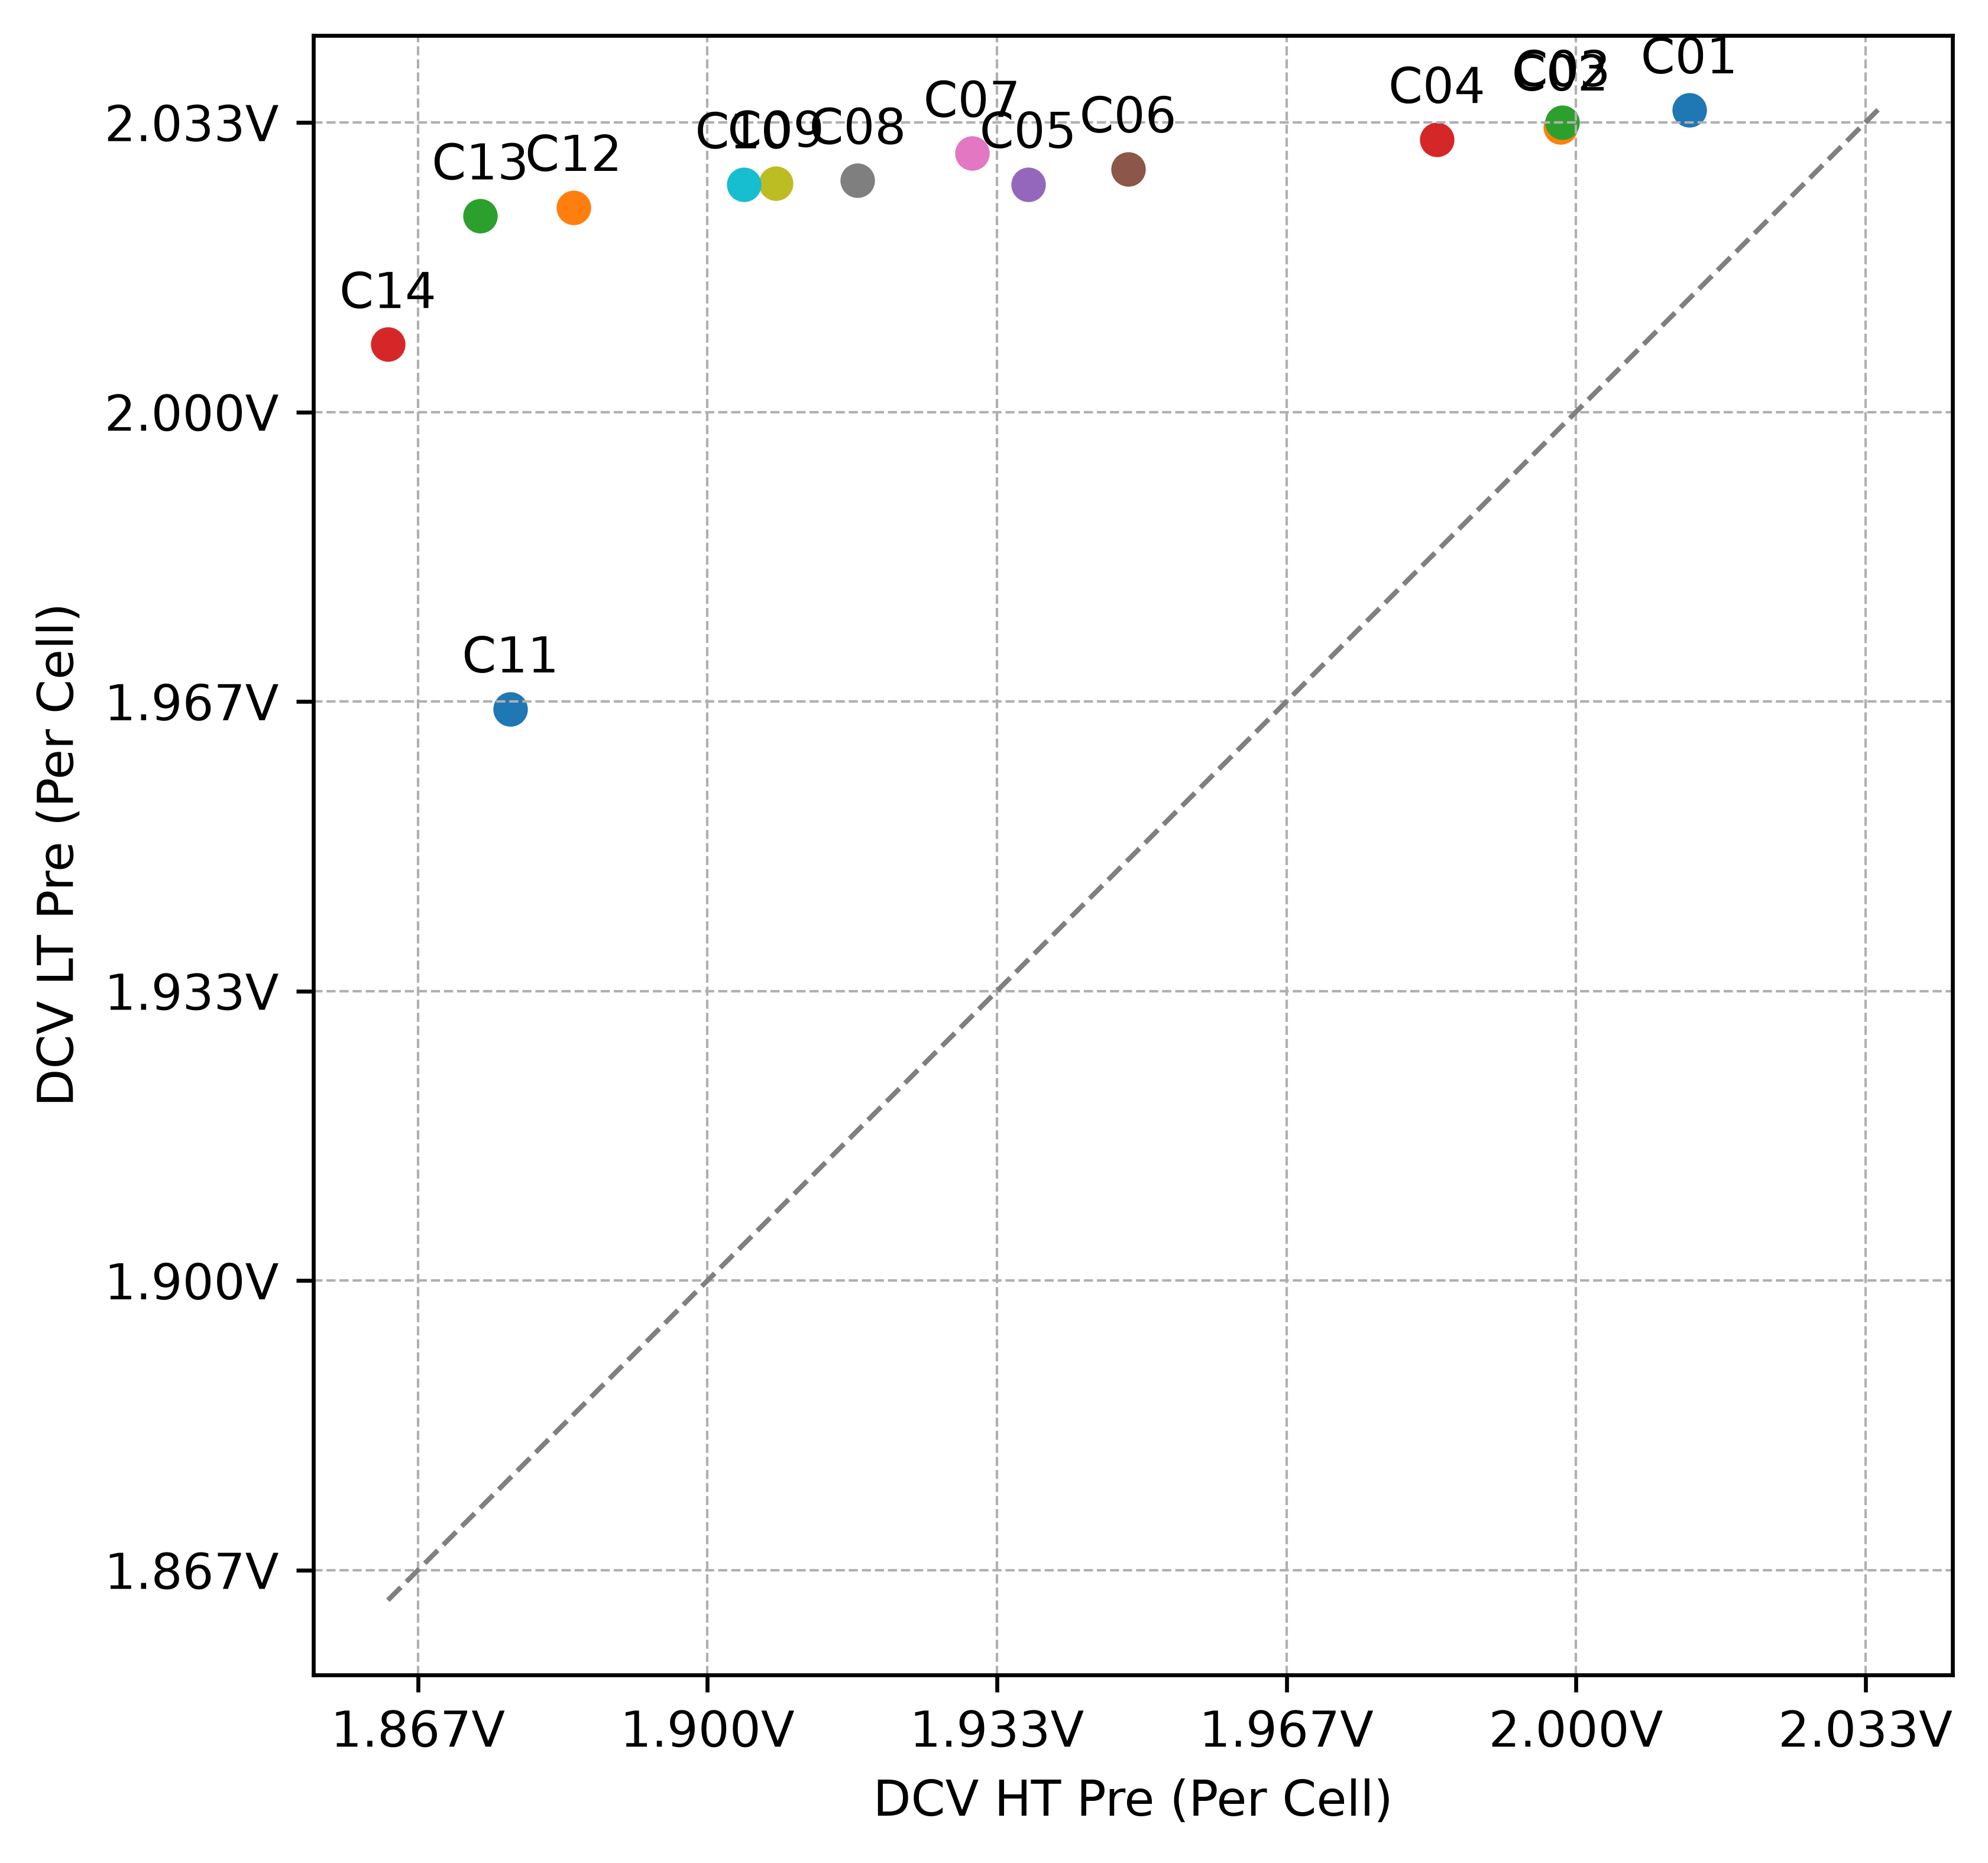

In [636]:
def plot_emf_data(emf_df: pd.DataFrame) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 6))

    for battery_id in emf_df["Battery"].unique():
        row = emf_df[emf_df["Battery"] == battery_id]
        ax.scatter(
            row["DCV HT Pre"],
            row["DCV LT Pre"],
            label=f"{battery_id}",
            marker="o",
        )
        ax.annotate(
            f"{battery_id}",
            (row["DCV HT Pre"].values[0], row["DCV LT Pre"].values[0]),
            textcoords="offset points",
            xytext=(0, 5),
            ha="center",
            va="bottom",
        )

    # Plot diagonal line for reference
    min_val = min(emf_df["DCV HT Pre"].min(), emf_df["DCV LT Pre"].min())
    max_val = max(emf_df["DCV HT Pre"].max(), emf_df["DCV LT Pre"].max())
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="gray",
        linestyle="--",
        linewidth=1,
    )

    # Equal aspect ratio
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)
    ax.set_xlabel("DCV HT Pre (Per Cell)")
    ax.set_ylabel("DCV LT Pre (Per Cell)")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/6:.3f}V"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/6:.3f}V"))

    return fig


plot_emf_data(emf_df)

In [637]:
FILTER_OUTLIERS = ["C11", "C14"]

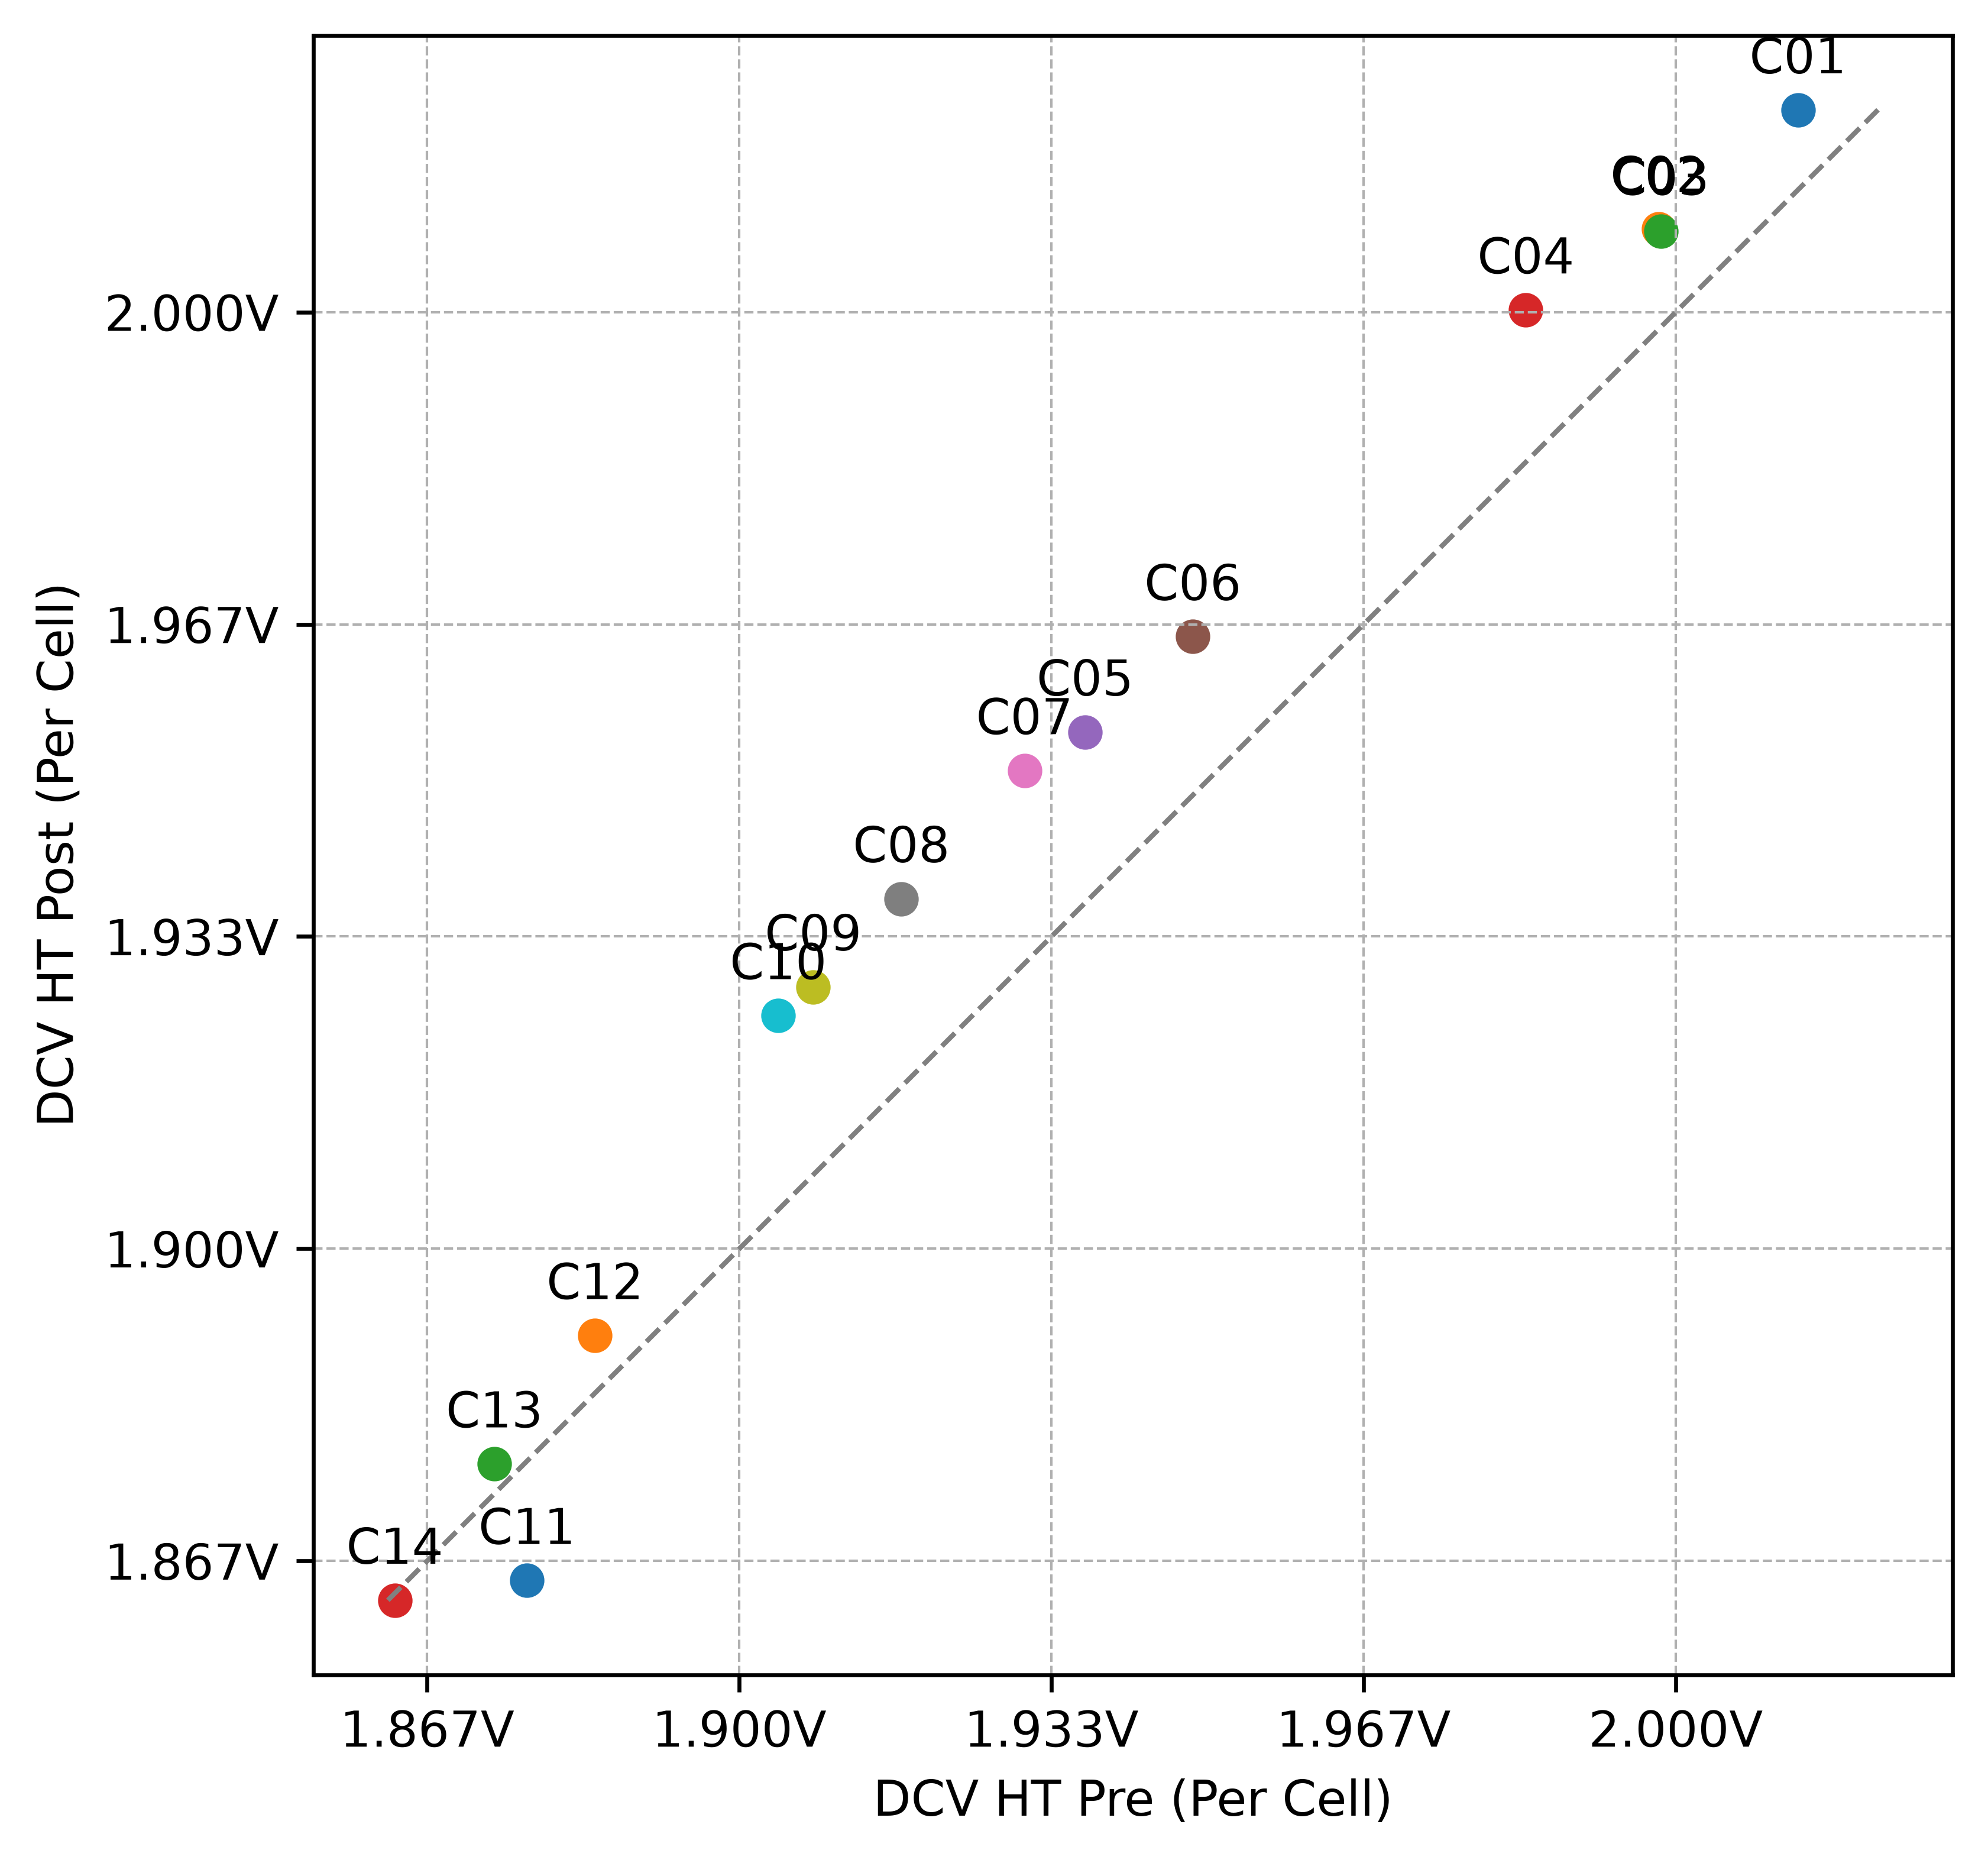

In [638]:
def plot_emf_pre_pst(emf_df: pd.DataFrame) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 6))

    for battery_id in emf_df["Battery"].unique():
        # if battery_id in FILTER_OUTLIERS:
        #     continue
        row = emf_df[emf_df["Battery"] == battery_id]
        ax.scatter(
            row["DCV HT Pre"],
            row["DCV HT Post"],
            label=f"{battery_id}",
            marker="o",
        )
        ax.annotate(
            f"{battery_id}",
            (row["DCV HT Pre"].values[0], row["DCV HT Post"].values[0]),
            textcoords="offset points",
            xytext=(0, 5),
            ha="center",
            va="bottom",
        )

    # Plot a reference line y=x
    min_val = min(emf_df["DCV HT Pre"].min(), emf_df["DCV HT Post"].min())
    max_val = max(emf_df["DCV HT Pre"].max(), emf_df["DCV HT Post"].max())
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="gray",
        linestyle="--",
        linewidth=1,
        label="y=x",
    )

    # Equal aspect ratio
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)
    ax.set_xlabel("DCV HT Pre (Per Cell)")
    ax.set_ylabel("DCV HT Post (Per Cell)")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/6:.3f}V"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/6:.3f}V"))

    return fig


plot_emf_pre_pst(emf_df)

In [639]:
def freezing_extent(emf_ht, emf_lt) -> float:
    """
    Calculate the freezing extent based on the high and low temperature EMF values as per Stanton et. al. (2026).
    """
    E_0 = 1.824
    return 1 - (emf_ht - E_0) / (emf_lt - E_0)

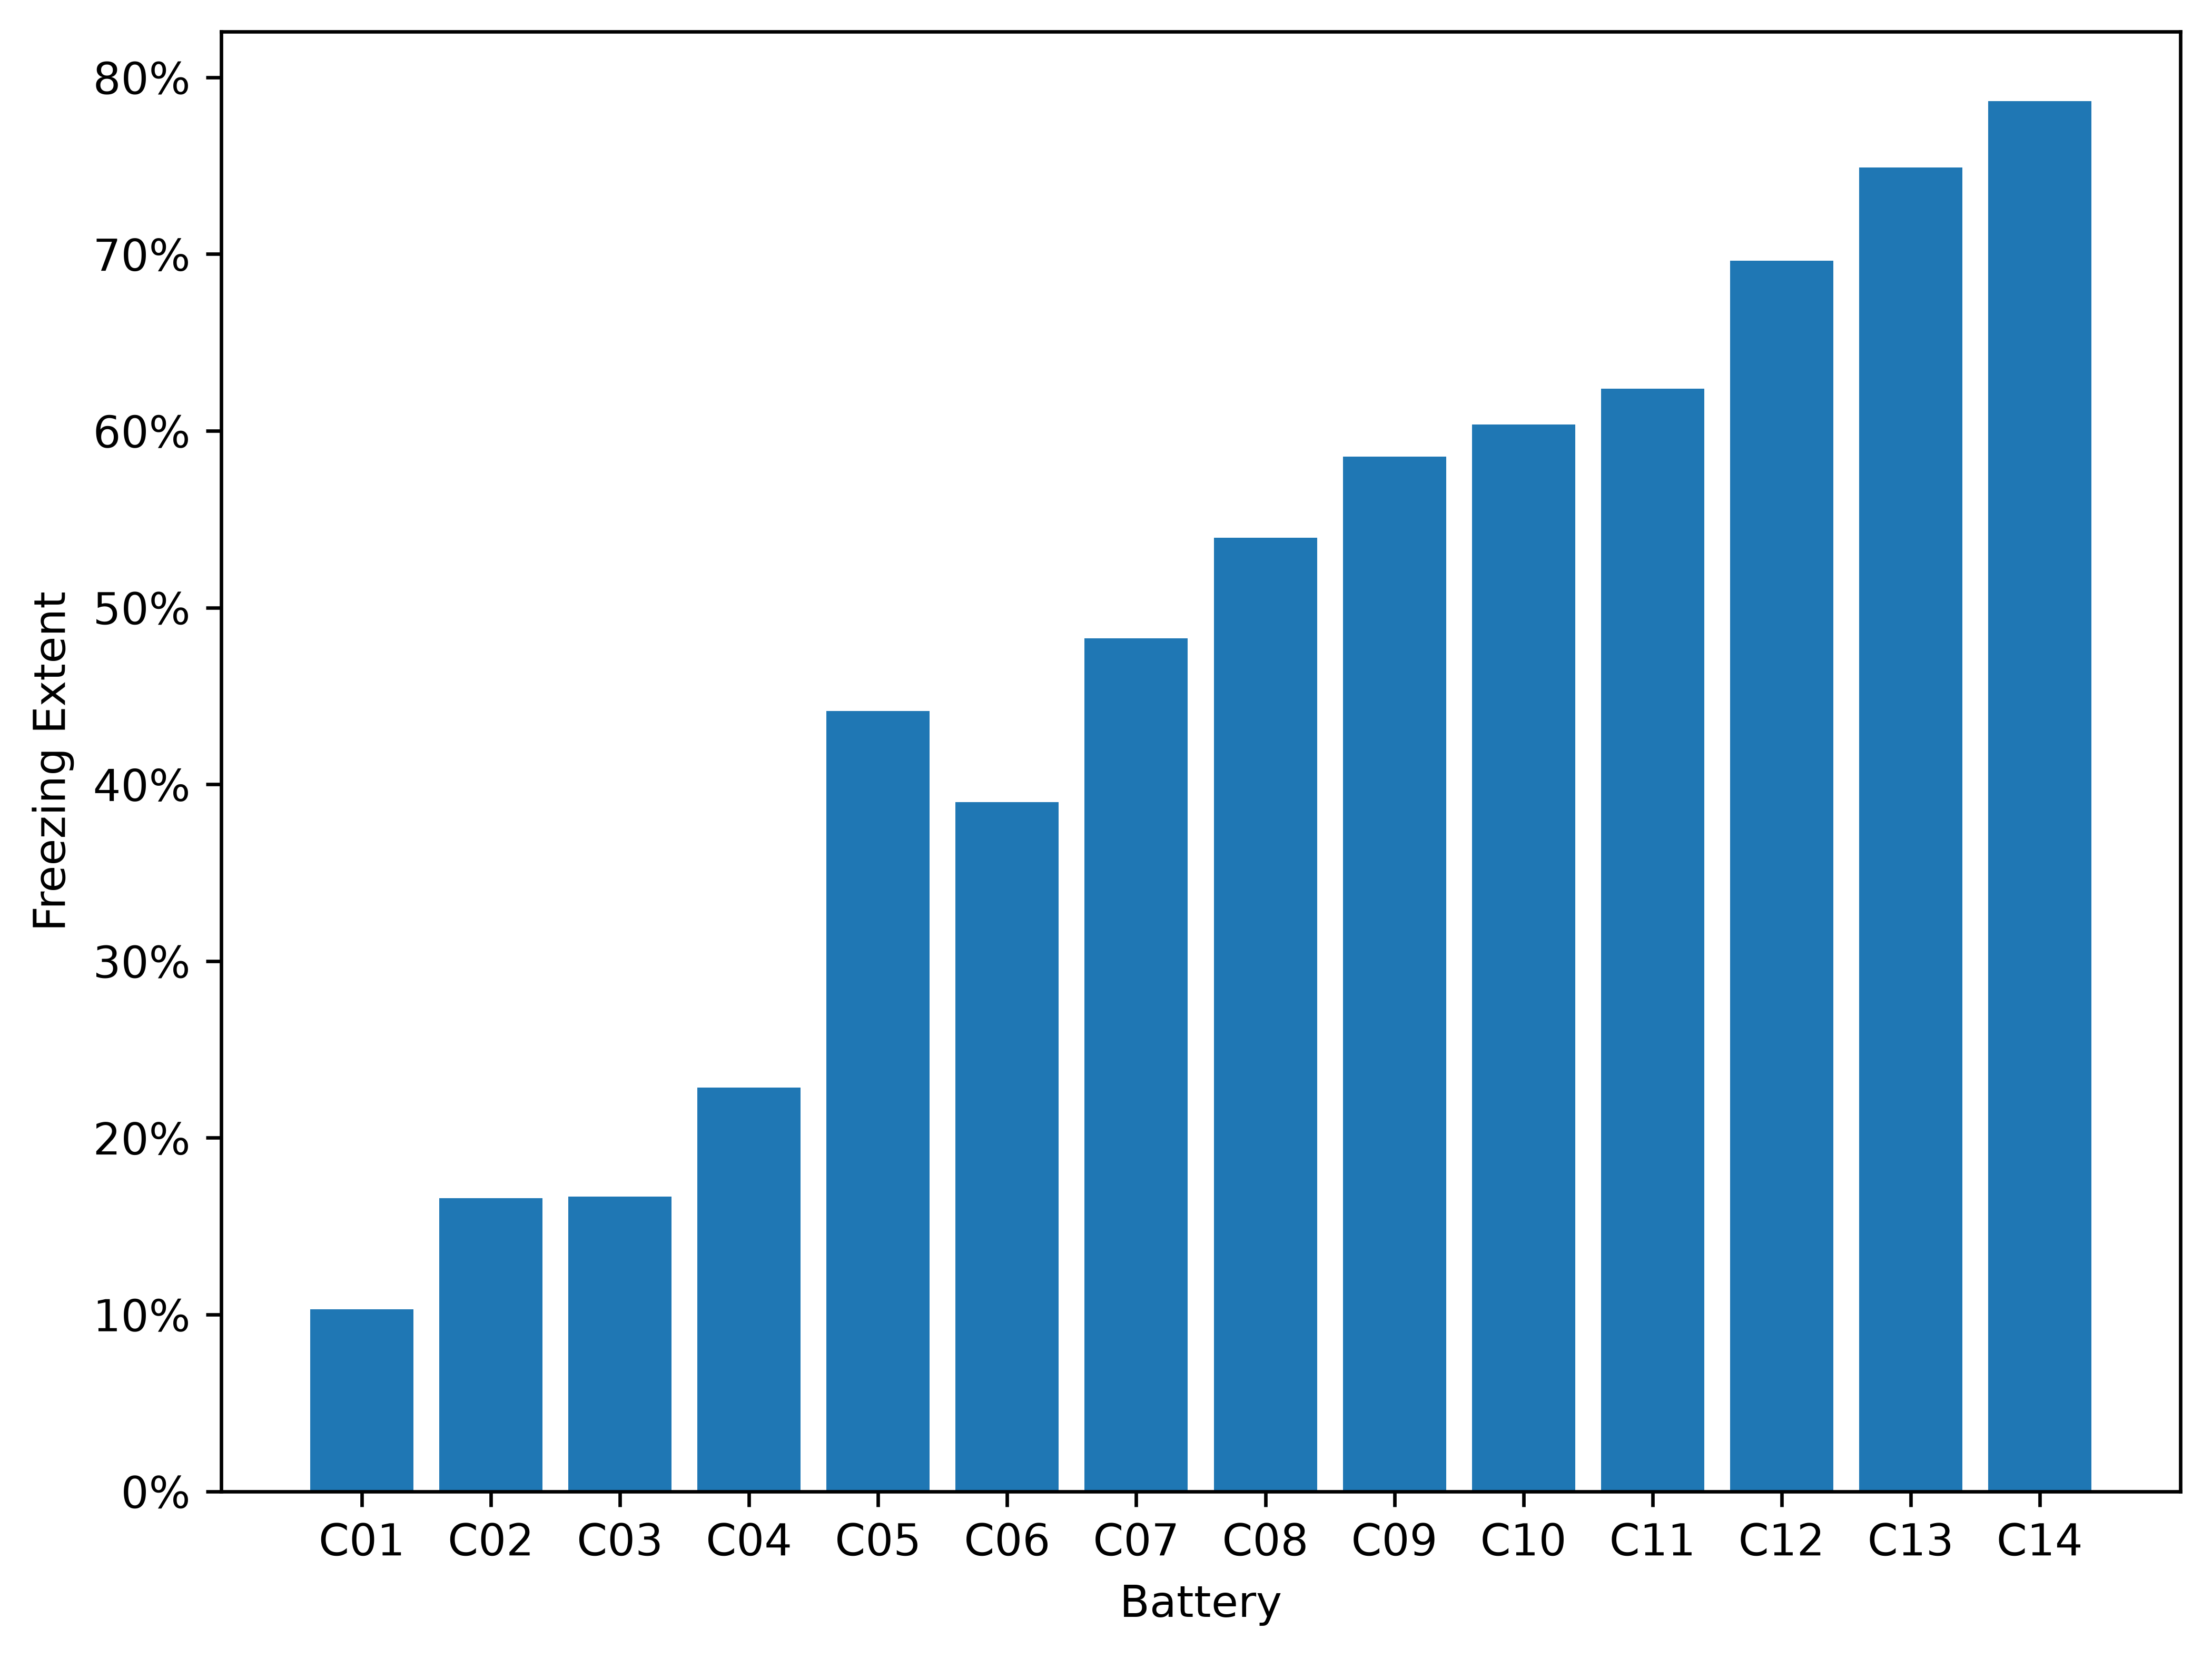

In [640]:
def plot_freezing_extent(emf_df: pd.DataFrame) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 6))

    freezing_extents = [
        freezing_extent(row["DCV HT Pre"] / 6, row["DCV LT Pre"] / 6)
        for _, row in emf_df.iterrows()
    ]

    ax.bar(emf_df["Battery"], freezing_extents)

    ax.set_xlabel("Battery")
    ax.set_ylabel("Freezing Extent")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))

    return fig


plot_freezing_extent(emf_df)

In [641]:
def find_recharge_files(data_path: str) -> List[str]:
    return [
        os.path.join(data_path, f) for f in os.listdir(data_path) if f.endswith(".csv")
    ]


def get_battery_from_file_name(file_name: str) -> str:
    idMatch = re.match(r".*-C(\d\d).csv", os.path.basename(file_name))
    if not idMatch:
        raise ValueError(
            f"Invalid file name format: {file_name}. Expected format: '...-CXX.csv' where XX is a two-digit number."
        )
    return f"C{idMatch.group(1)}"


def load_recharge_data(file_path: str) -> pd.DataFrame:
    HEADER_ROWS = 8

    def metadata(metadata_str: str) -> Dict[str, Any]:
        metadata_dict = {}
        for line in metadata_str.splitlines():
            if "," in line:
                key, value = line.split(",", 1)
                metadata_dict[key.strip()] = value.strip()

        return metadata_dict

    print(f"Loading recharge data from {file_path}...")

    df = pd.read_csv(
        file_path,
        skiprows=HEADER_ROWS,
    )
    df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
    df.rename(
        columns={
            "V2(V)": "Voltage",
            "I2(A)": "Current",
        },
        inplace=True,
    )

    start_time = pd.to_datetime(df["Time Stamp"].iloc[0])
    df["Time"] = (
        pd.to_datetime(df["Time Stamp"]) - start_time
    ).dt.total_seconds() / 60.0  # Time in minutes

    df["Charge"] = np.cumsum(
        df["Current"] * (df["Time"].diff().fillna(0) / 60.0)
    )  # Charge in Ah

    df.attrs["metadata"] = metadata(
        "\n".join(open(file_path).readlines()[:HEADER_ROWS])
    )
    df.attrs.update({"Battery": get_battery_from_file_name(file_path)})

    return df


recharge_data = {
    get_battery_from_file_name(f): load_recharge_data(f)
    for f in find_recharge_files(VOLTS_CURRENT_DATA_DIR)
}
recharge_data = dict(sorted(recharge_data.items(), key=lambda item: item[0]))

Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C08.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C09.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C02.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C03.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C01.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C14.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C04.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C10.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C11.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C05.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C13.csv...
Loading recharge data from ../Data/Recharge/Electric/SISPS-BATT-RECHG-LT-C07

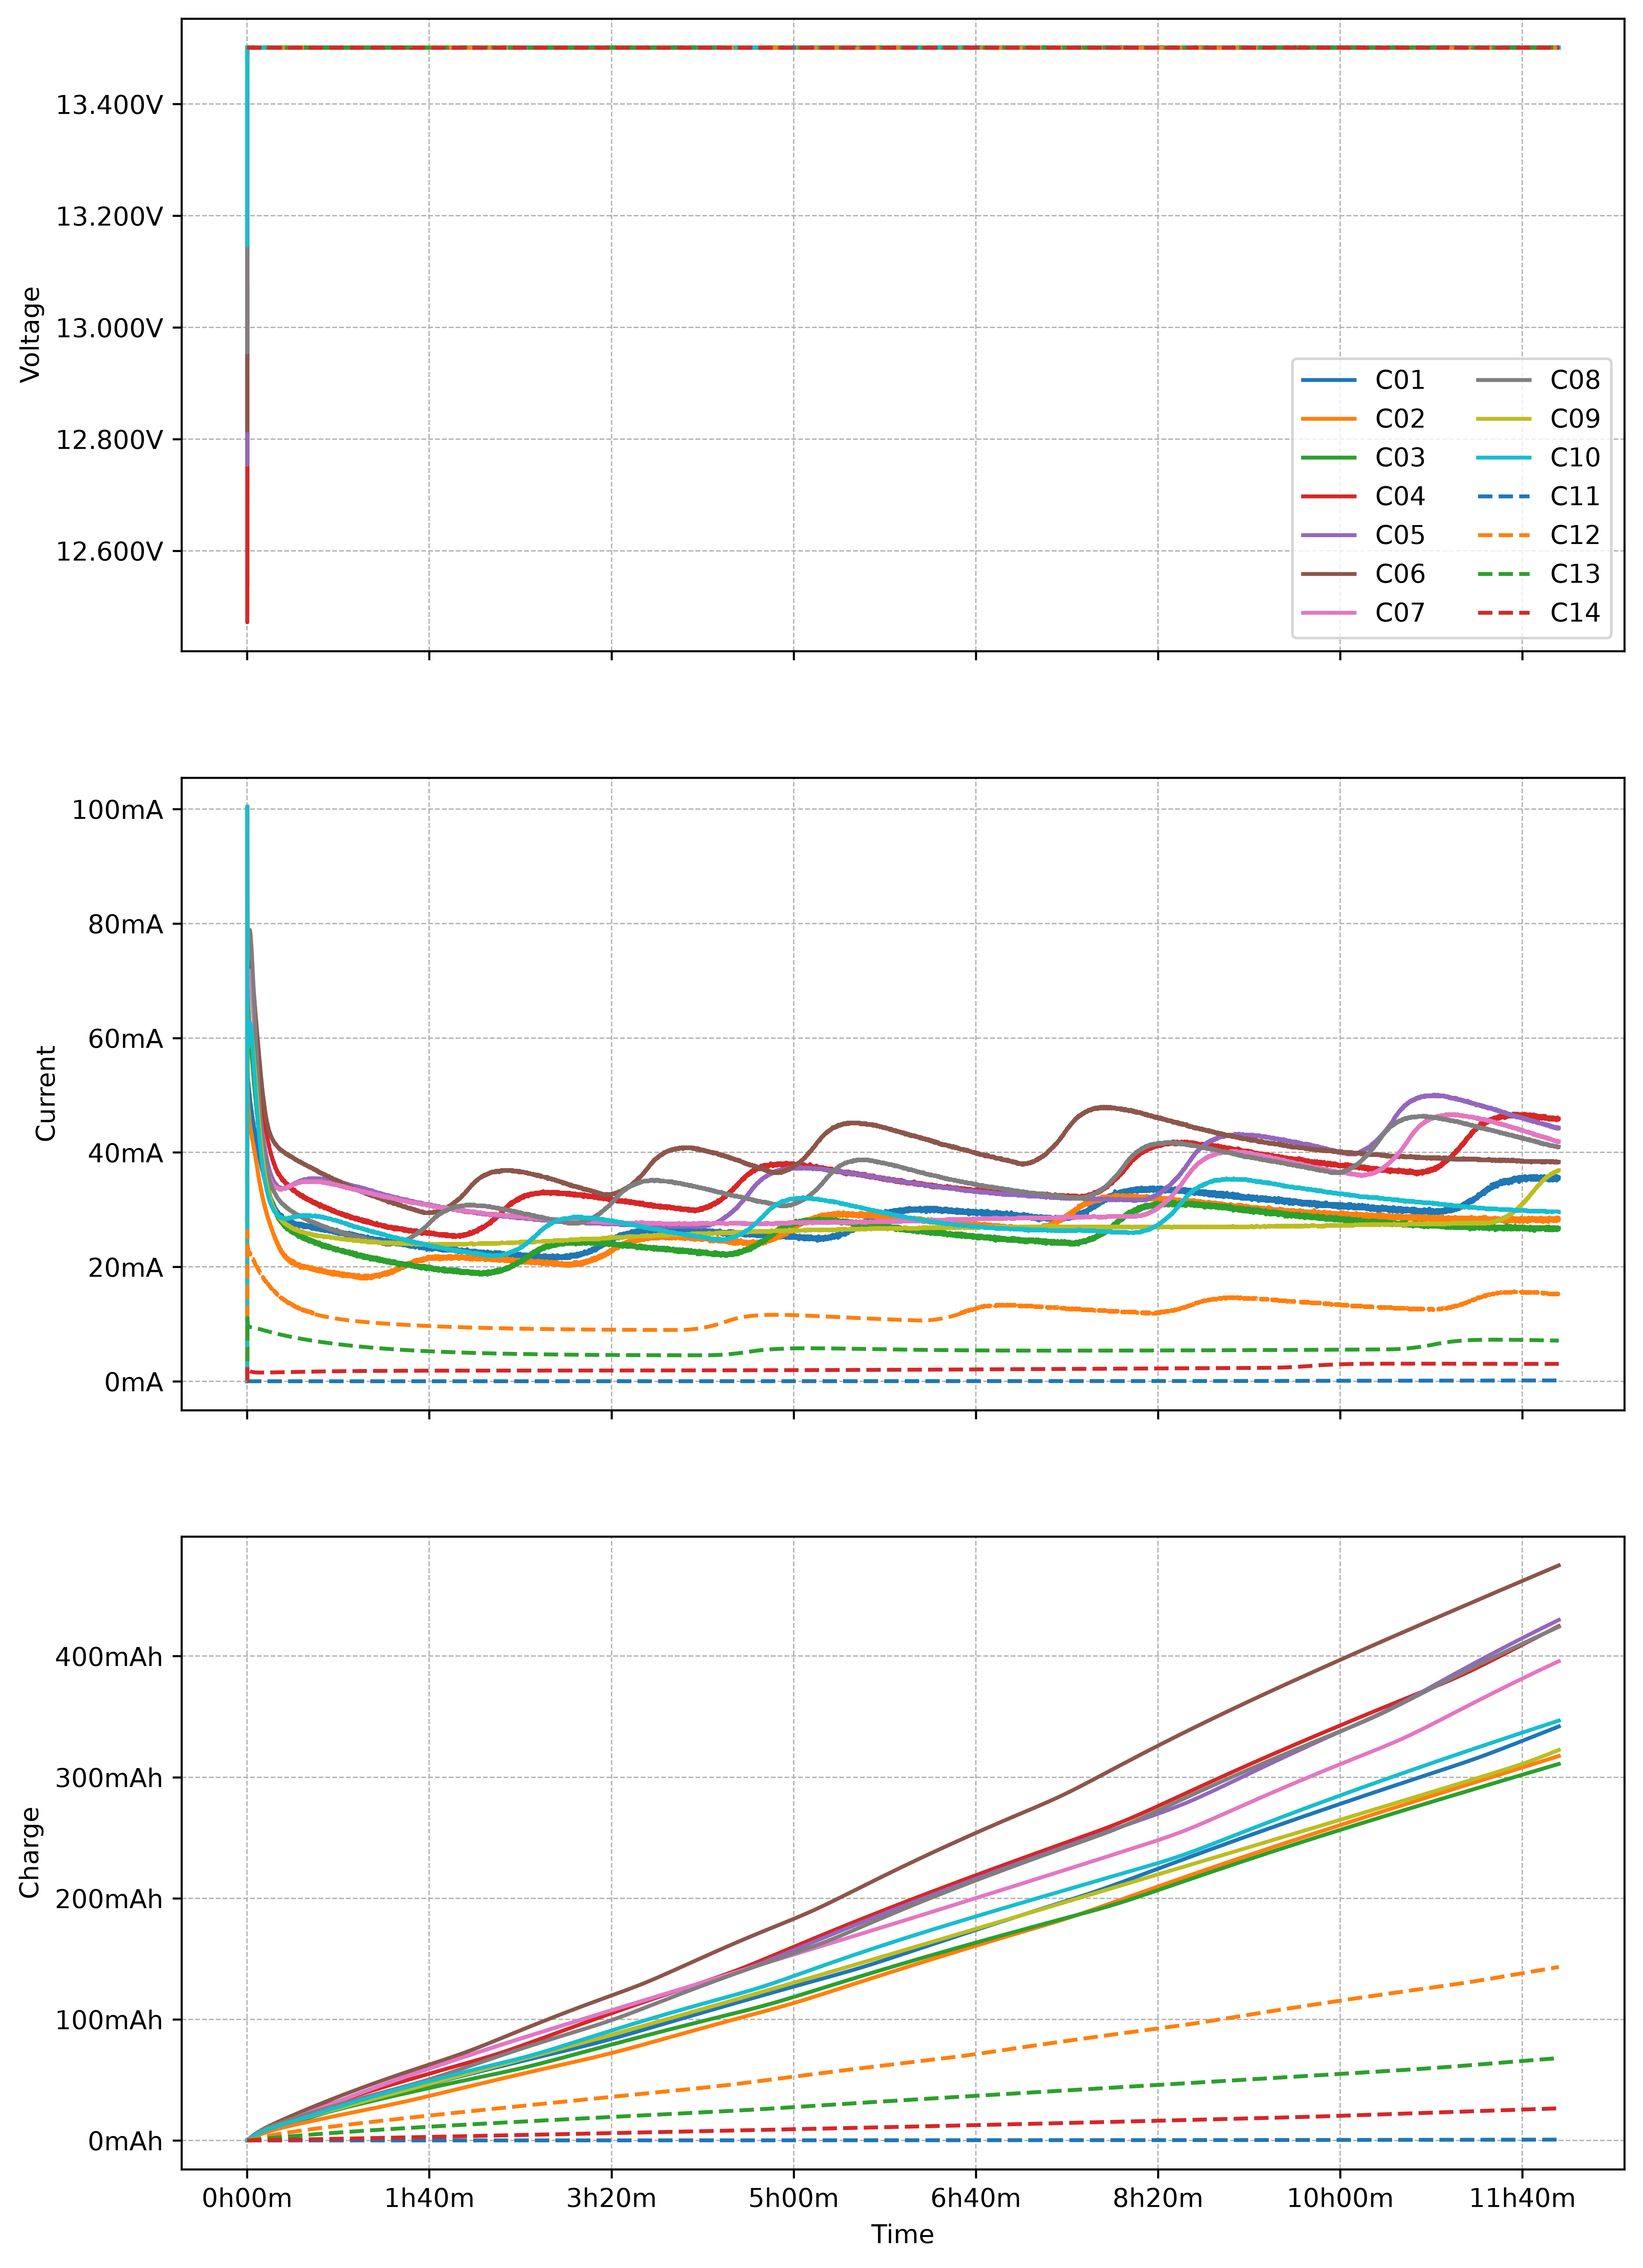

In [642]:
def plot_recharge_data(recharge_data: Dict[str, pd.DataFrame]) -> Figure:
    fig, ax = plt.subplots(3, 1, figsize=(10, 15), sharex=True)

    for battery_id, df in recharge_data.items():
        ax[0].plot(df["Time"], df["Voltage"], label=f"{battery_id}")
        ax[1].plot(df["Time"], df["Current"], label=f"{battery_id}")
        ax[2].plot(df["Time"], df["Charge"], label=f"{battery_id}")

    ax[0].legend(ncol=2)
    ax[0].set_ylabel("Voltage")
    ax[0].grid(True, which="both", linestyle="--", linewidth=0.5)
    ax[0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.3f}V"))

    ax[1].set_ylabel("Current")
    ax[1].grid(True, which="both", linestyle="--", linewidth=0.5)
    ax[1].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}mA"))

    ax[2].set_xlabel("Time")
    ax[2].xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f"{(x//60):.0f}h{(x%60):02.0f}m")
    )
    ax[2].set_ylabel("Charge")
    ax[2].grid(True, which="both", linestyle="--", linewidth=0.5)
    ax[2].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}mAh"))

    return fig


plot_recharge_data(recharge_data)

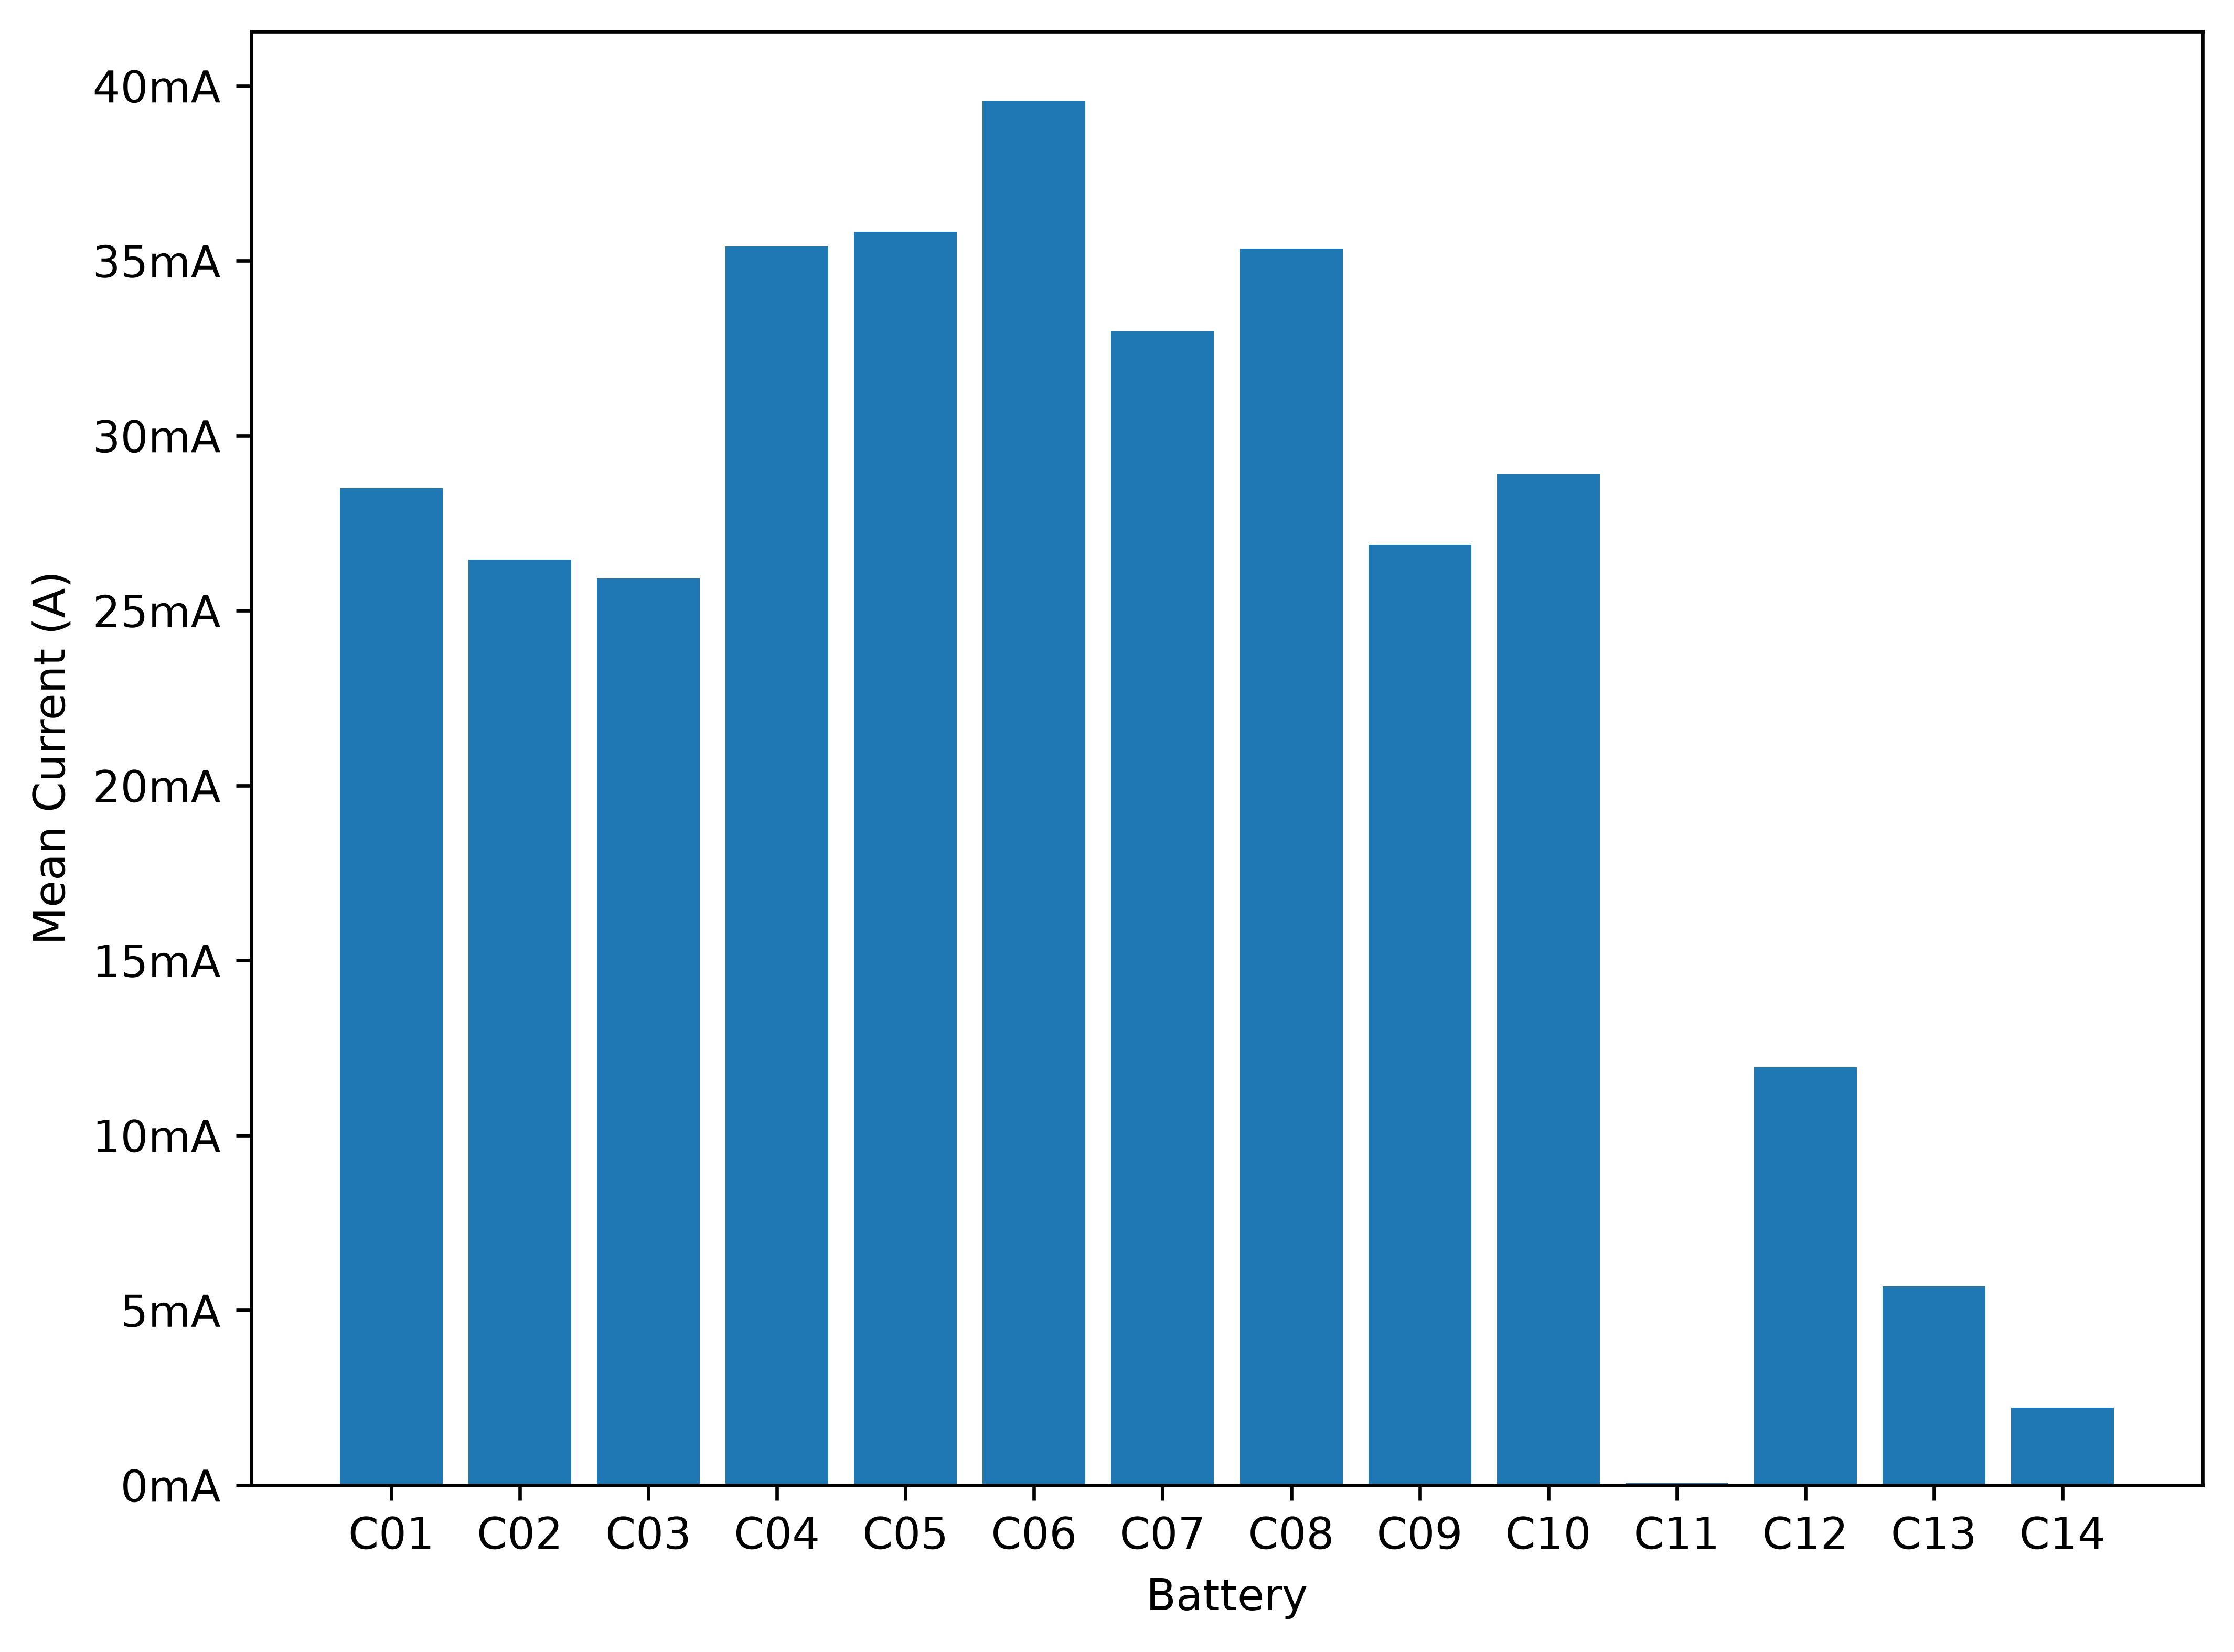

In [654]:
def plot_mean_current(recharge_data: Dict[str, pd.DataFrame]) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 6))

    mean_currents = {
        battery_id: df["Current"].mean() for battery_id, df in recharge_data.items()
    }

    ax.bar(mean_currents.keys(), mean_currents.values())

    ax.set_xlabel("Battery")
    ax.set_ylabel("Mean Current (A)")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}mA"))

    return fig


plot_mean_current(recharge_data)

In [643]:
def find_temperature_files(data_path: str) -> List[str]:
    return [
        os.path.join(data_path, f) for f in os.listdir(data_path) if f.endswith(".csv")
    ]


def load_temperature_data(file_path: str) -> pd.DataFrame:
    HEADER_ROWS = 25

    def metadata(metadata_str: str) -> Dict[str, Any]:
        metadata_dict = {}
        for line in metadata_str.splitlines():
            if "," in line:
                key, value = line.split(",", 1)
                metadata_dict[key.strip()] = value.strip()

        return metadata_dict

    print(f"Loading temperature data from {file_path}...")

    df = pd.read_csv(
        file_path,
        skiprows=HEADER_ROWS,
    )
    df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

    start_time = pd.to_datetime(df["Time Stamp(s)"].iloc[0])
    df["Time"] = (
        pd.to_datetime(df["Time Stamp(s)"]) - start_time
    ).dt.total_seconds() / 60.0  # Time in minutes

    df.attrs["metadata"] = metadata(
        "\n".join(open(file_path).readlines()[:HEADER_ROWS])
    )
    df.attrs.update({"Battery": get_battery_from_file_name(file_path)})

    return df


temperature_data = {
    get_battery_from_file_name(f): load_temperature_data(f)
    for f in find_temperature_files(TEMPERATURE_DATA_DIR)
}
temperature_data = dict(sorted(temperature_data.items(), key=lambda item: item[0]))

Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C08.csv...
Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C09.csv...
Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C01.csv...
Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C14.csv...
Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C02.csv...
Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C03.csv...
Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C13.csv...
Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C07.csv...
Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C06.csv...
Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C12.csv...
Loading temperature data from ../Data/Recharge/Temperature/SISPS-BATT-TEMP-LT-C04.csv...
Loading temperature d

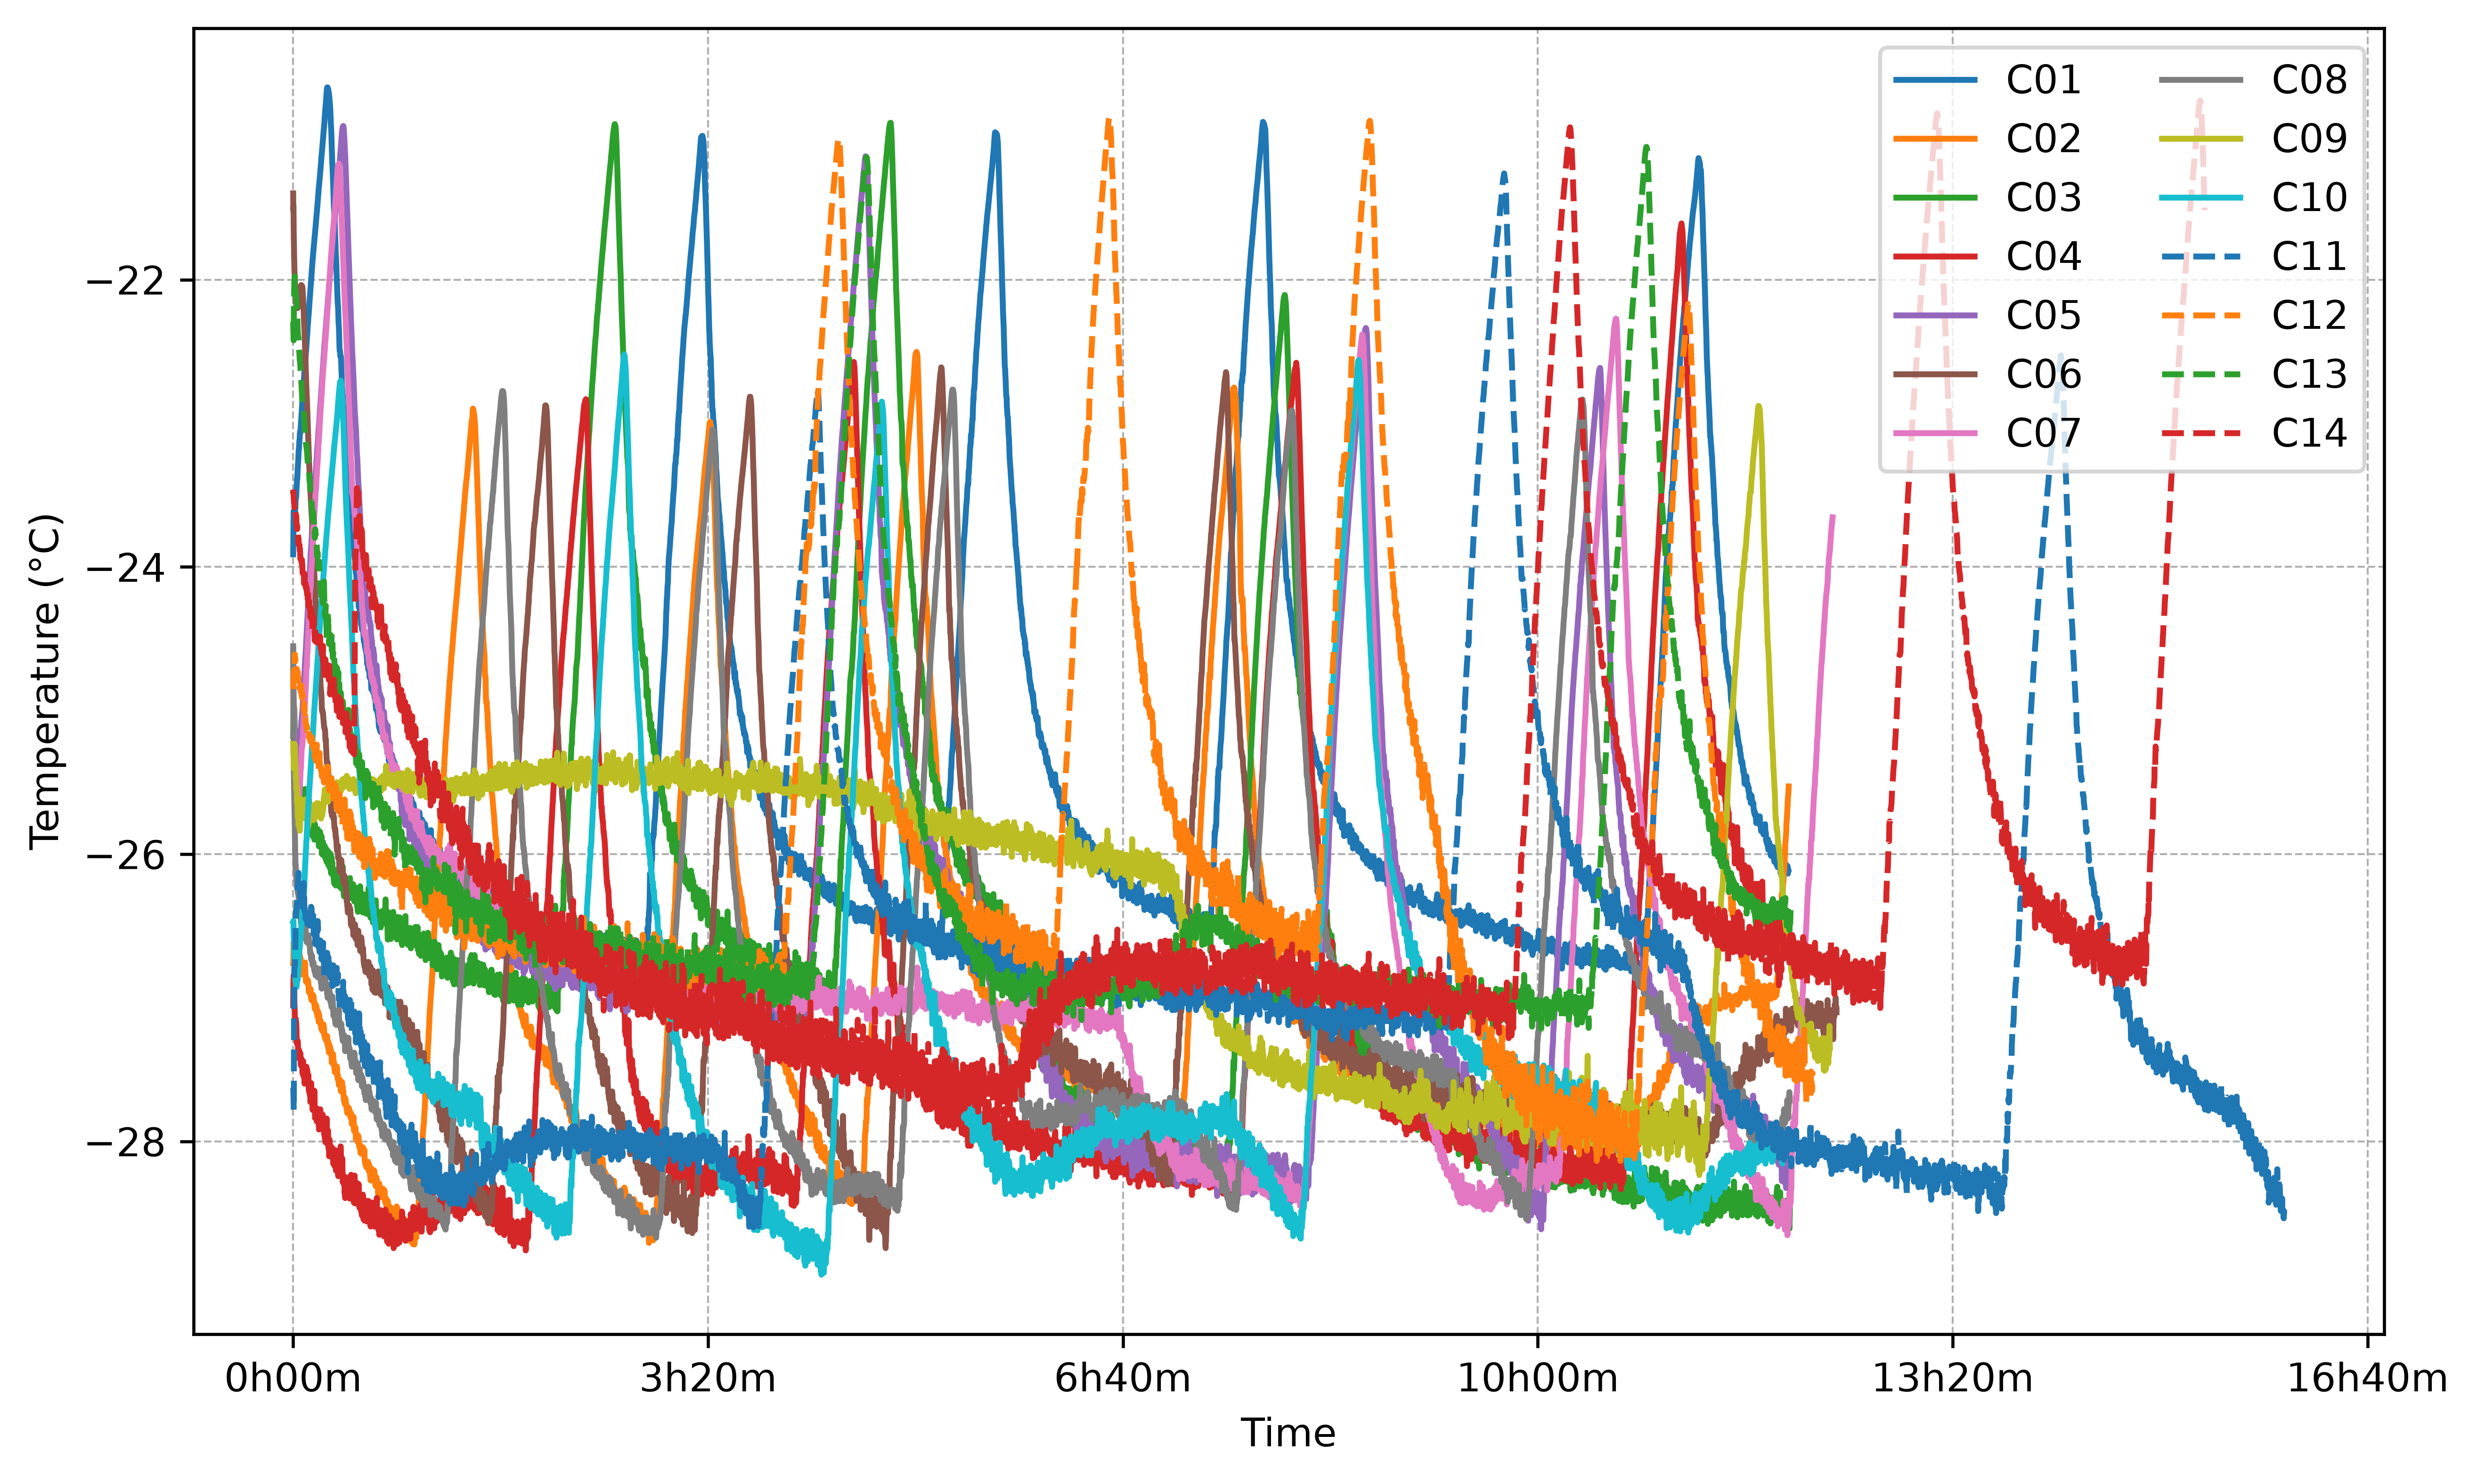

In [644]:
def plot_temperature_data(temperature_data: Dict[str, pd.DataFrame]) -> Figure:
    fig, ax = plt.subplots(figsize=(10, 6))

    for battery_id, df in temperature_data.items():
        ax.plot(df["Time"], df["Temperature (C)"], label=f"{battery_id}")

    ax.legend(ncol=2)
    ax.set_xlabel("Time")
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f"{(x//60):.0f}h{(x%60):02.0f}m")
    )
    ax.set_ylabel("Temperature (°C)")
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)

    return fig


plot_temperature_data(temperature_data)

## Comparative Analysis

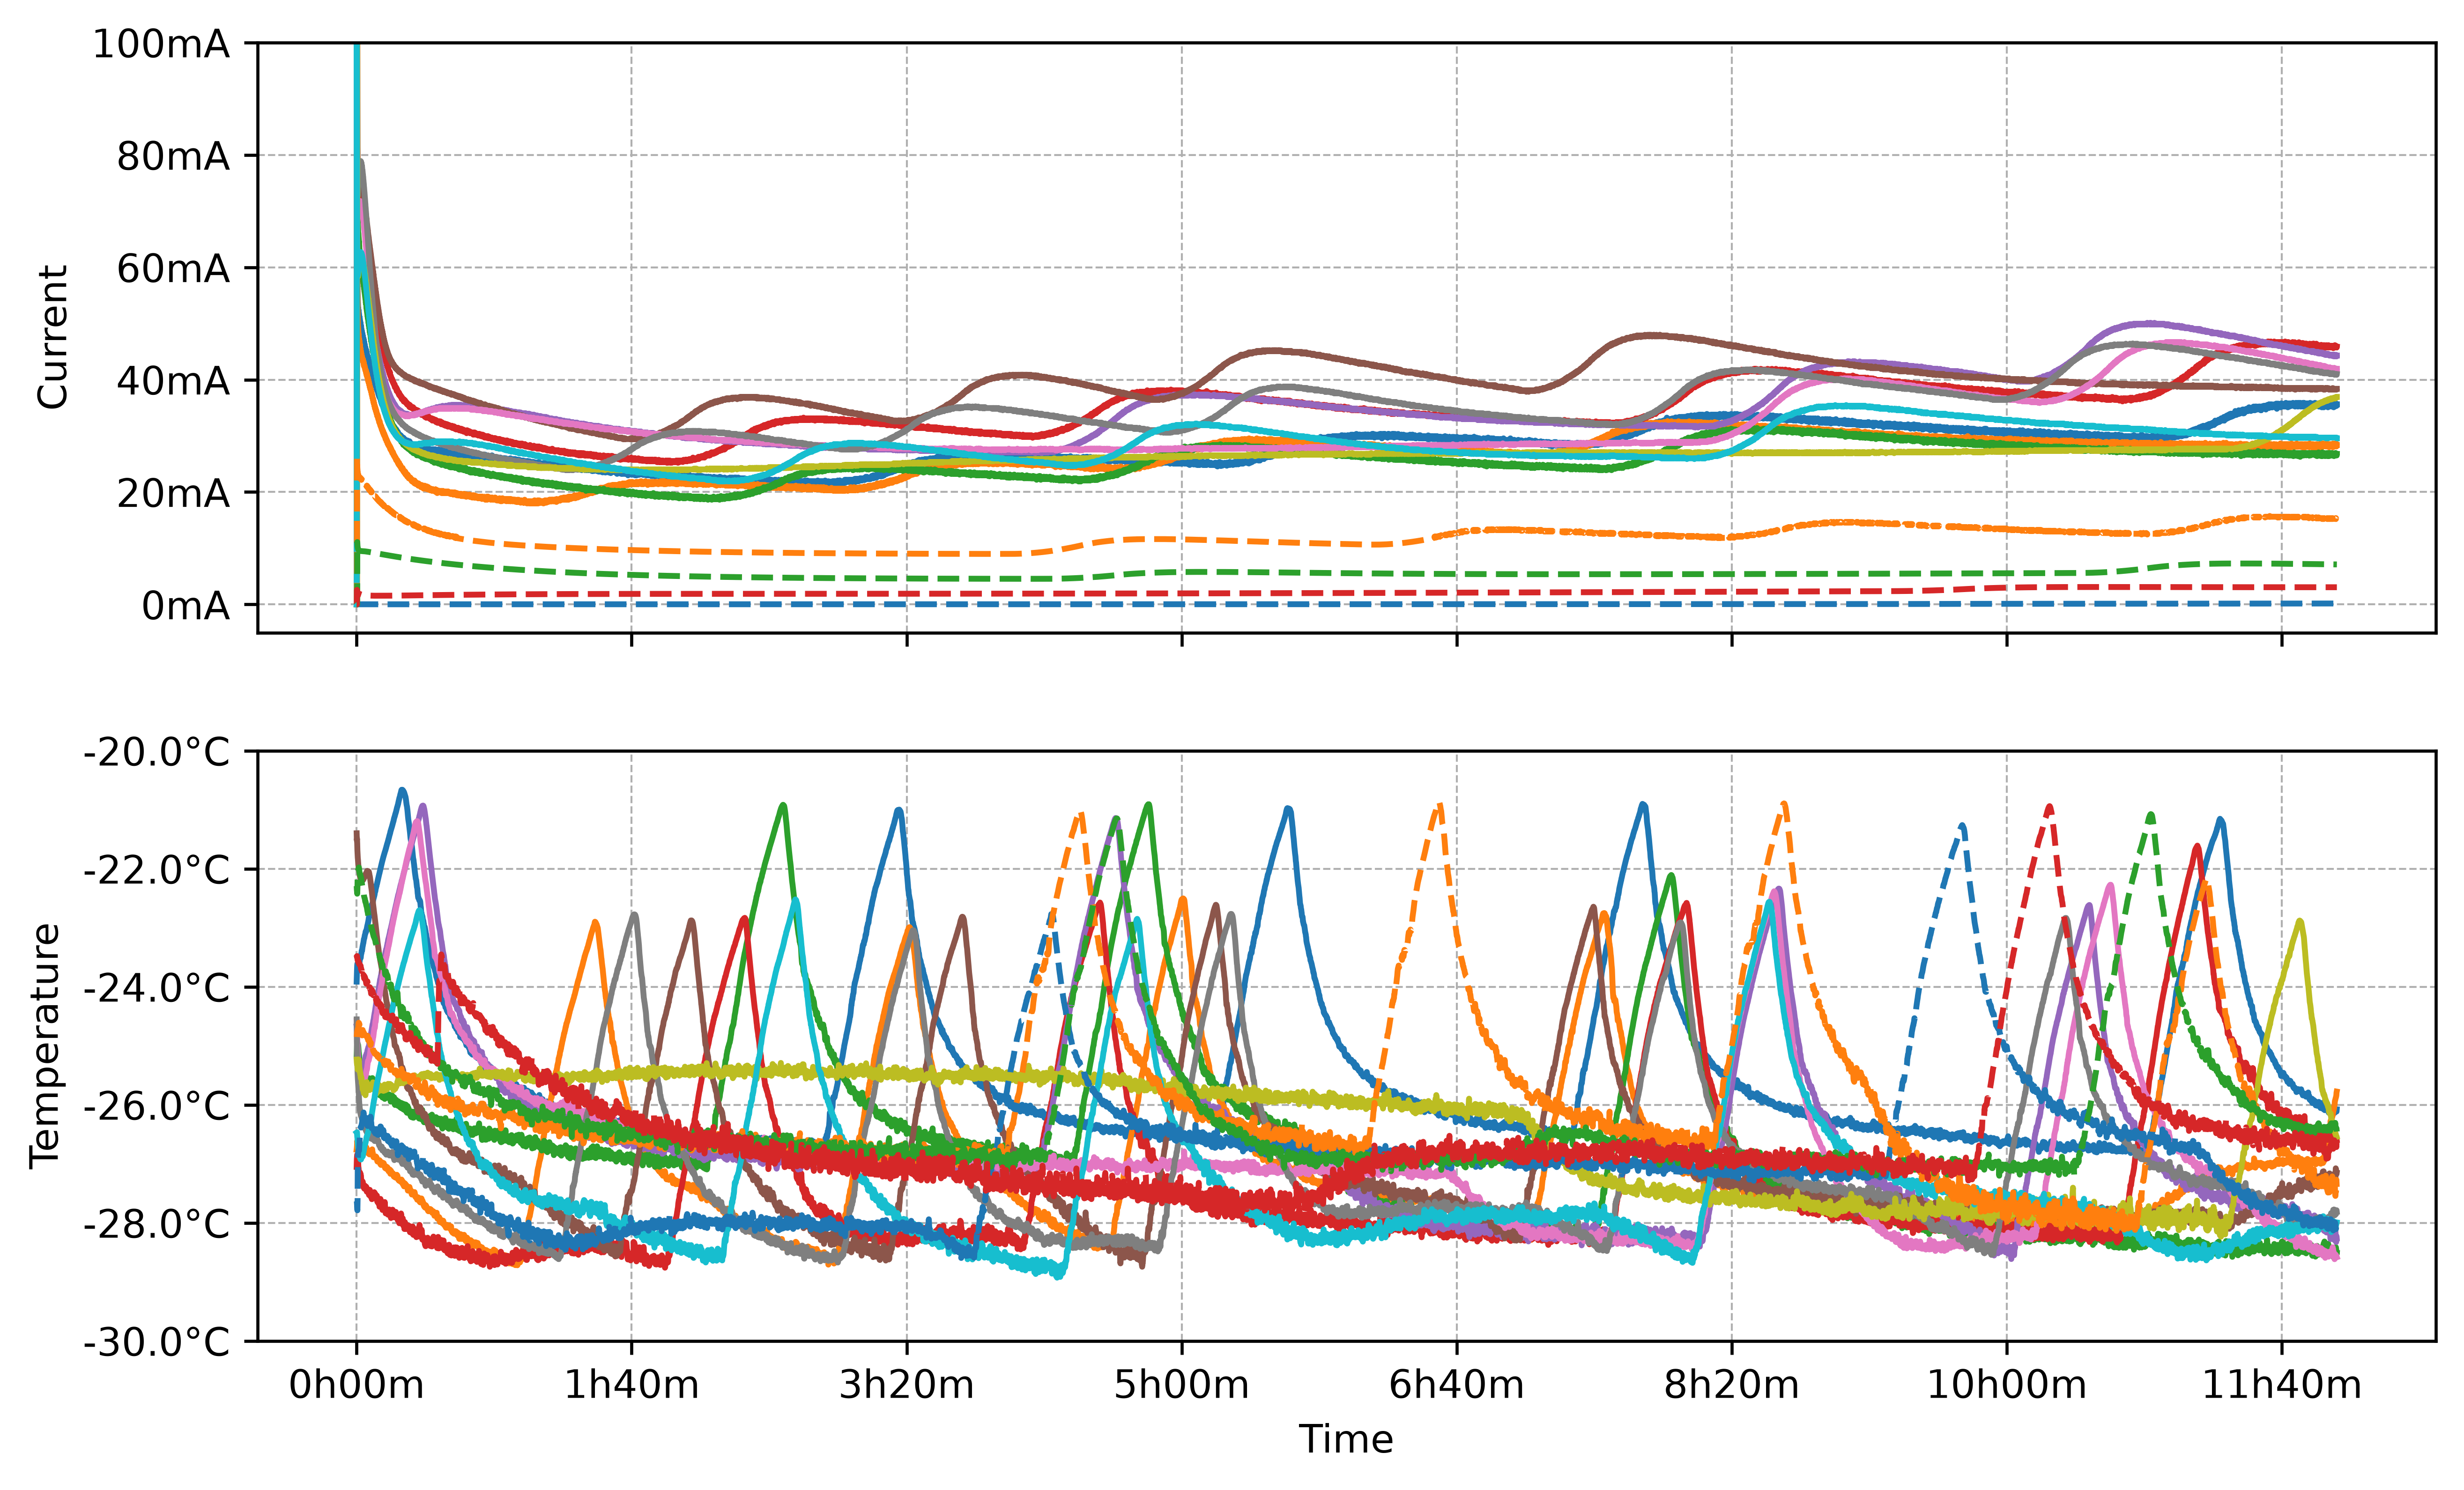

In [645]:
def plot_current_temperature(
    recharge_data: Dict[str, pd.DataFrame],
    temperature_data: Dict[str, pd.DataFrame],
    battery_ids: Optional[List[str]] = None,
) -> Figure:
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    if battery_ids is None:
        battery_ids = list(recharge_data.keys())

    for battery_id in battery_ids:
        if battery_id in temperature_data:
            df_recharge = deepcopy(recharge_data[battery_id])
            df_temp = deepcopy(temperature_data[battery_id])

            # Trim the data to the overlapping time range
            max_time = min(df_recharge["Time"].max(), df_temp["Time"].max())
            time_mask_recharge = df_recharge["Time"] <= max_time
            time_mask_temp = df_temp["Time"] <= max_time
            df_recharge = df_recharge[time_mask_recharge]
            df_temp = df_temp[time_mask_temp]

            ax1.plot(df_recharge["Time"], df_recharge["Current"], label=f"{battery_id}")
            ax2.plot(df_temp["Time"], df_temp["Temperature (C)"], label=f"{battery_id}")

    ax1.set_ylabel("Current")
    ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}mA"))
    ax1.grid(True, which="both", linestyle="--", linewidth=0.5)
    ax1.set_ylim(top=0.1)

    ax2.set_xlabel("Time")
    ax2.xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f"{(x//60):.0f}h{(x%60):02.0f}m")
    )
    ax2.set_ylabel("Temperature")
    ax2.grid(True, which="both", linestyle="--", linewidth=0.5)
    ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1f}°C"))
    ax2.set_ylim(bottom=-30, top=-20)

    return fig


plot_current_temperature(recharge_data, temperature_data)

In [646]:
for battery_id in recharge_data.keys():
    if battery_id in temperature_data:
        fig = plot_current_temperature(
            recharge_data, temperature_data, battery_ids=[battery_id]
        )
        fig.suptitle(f"Battery {battery_id} Current and Temperature Over Time")
        fig.tight_layout()
        fig.savefig(os.path.join(PLOT_OUTPUT_DIR, f"{battery_id}_IT.png"))

In [647]:
# Constants
FARADAY_CONSTANT = 96485.33212  # C/mol
NUM_ELECTRONS = 2  # For lead-acid batteries

M_H2SO4 = 98.07  # g/mol for H2SO4
M_H2O = 18.015  # g/mol for H2O


def mole_fraction(a: float) -> float:
    """
    Calculate the mole fraction of the electrolyte based on the mass fraction.
    """
    return 1 / (1 + ((1 - a) / a) * (M_H2SO4 / M_H2O))

In [648]:
def calculate_recharge_ah_emf(
    emf_pre: float, emf_post: float, mol_electrolyte: float
) -> float:
    """
    Calculate the amount of moles of recharge applied to the battery based on the prior and post EMF measurements and the moles of electrolyte in the lead acid cell.

    Returns the number of moles of recharge applied to the battery.

    Args:
        emf_pre (float): The EMF measurement before the recharge.
        emf_post (float): The EMF measurement after the recharge.
        mol_electrolyte (float): The moles of electrolyte in the lead acid cell (constant).

    Returns:
        float: The number of Amp hours of recharge applied to the battery.
    """

    def mass_fraction(emf: float) -> float:
        """
        Calculate the mass fraction of the electrolyte based on the EMF measurement.
        """
        E_0 = 1.824  # Standard EMF for lead-acid battery
        A_0 = 0.784

        return (emf - E_0) / A_0

    a_0 = mass_fraction(emf_pre)
    a_1 = mass_fraction(emf_post)

    x_0 = mole_fraction(a_0)
    x_1 = mole_fraction(a_1)

    # Calculate the change in mole fraction
    delta_n = (x_1 - x_0) * mol_electrolyte

    q = delta_n * NUM_ELECTRONS * FARADAY_CONSTANT  # Charge in Coulombs

    # Convert Coulombs to Amp hours
    return q / (3600)

In [649]:
def mol_electrolyte(capacity: float, full_charge_mass_fraction: float) -> float:
    """
    Calculate the moles of electrolyte in a lead-acid battery based on its full capacity and the mass fraction of the electrolyte at full charge.

    Args:
        capacity (float): The capacity of the battery in Amp hours (Ah).
        full_charge_mass_fraction (float): The mass fraction of the electrolyte at full charge.

    Returns:
        float: The number of moles of electrolyte in the battery.
    """
    M_H2SO4 = 98.07  # g/mol for H2SO4
    M_H2O = 18.015  # g/mol for H2O

    # Calculate the mass of the electrolyte in grams
    mol_frac = mole_fraction(full_charge_mass_fraction)
    z = 2

    n = (capacity * 3600) / (z * FARADAY_CONSTANT) / mol_frac  # moles of electrolyte

    return n


MOL_ELECTROLYTE = mol_electrolyte(
    capacity=6.54, full_charge_mass_fraction=0.42
)  # Example values for a lead-acid battery
print(f"Moles of electrolyte in the battery: {MOL_ELECTROLYTE:.2f} mol")

Moles of electrolyte in the battery: 1.04 mol


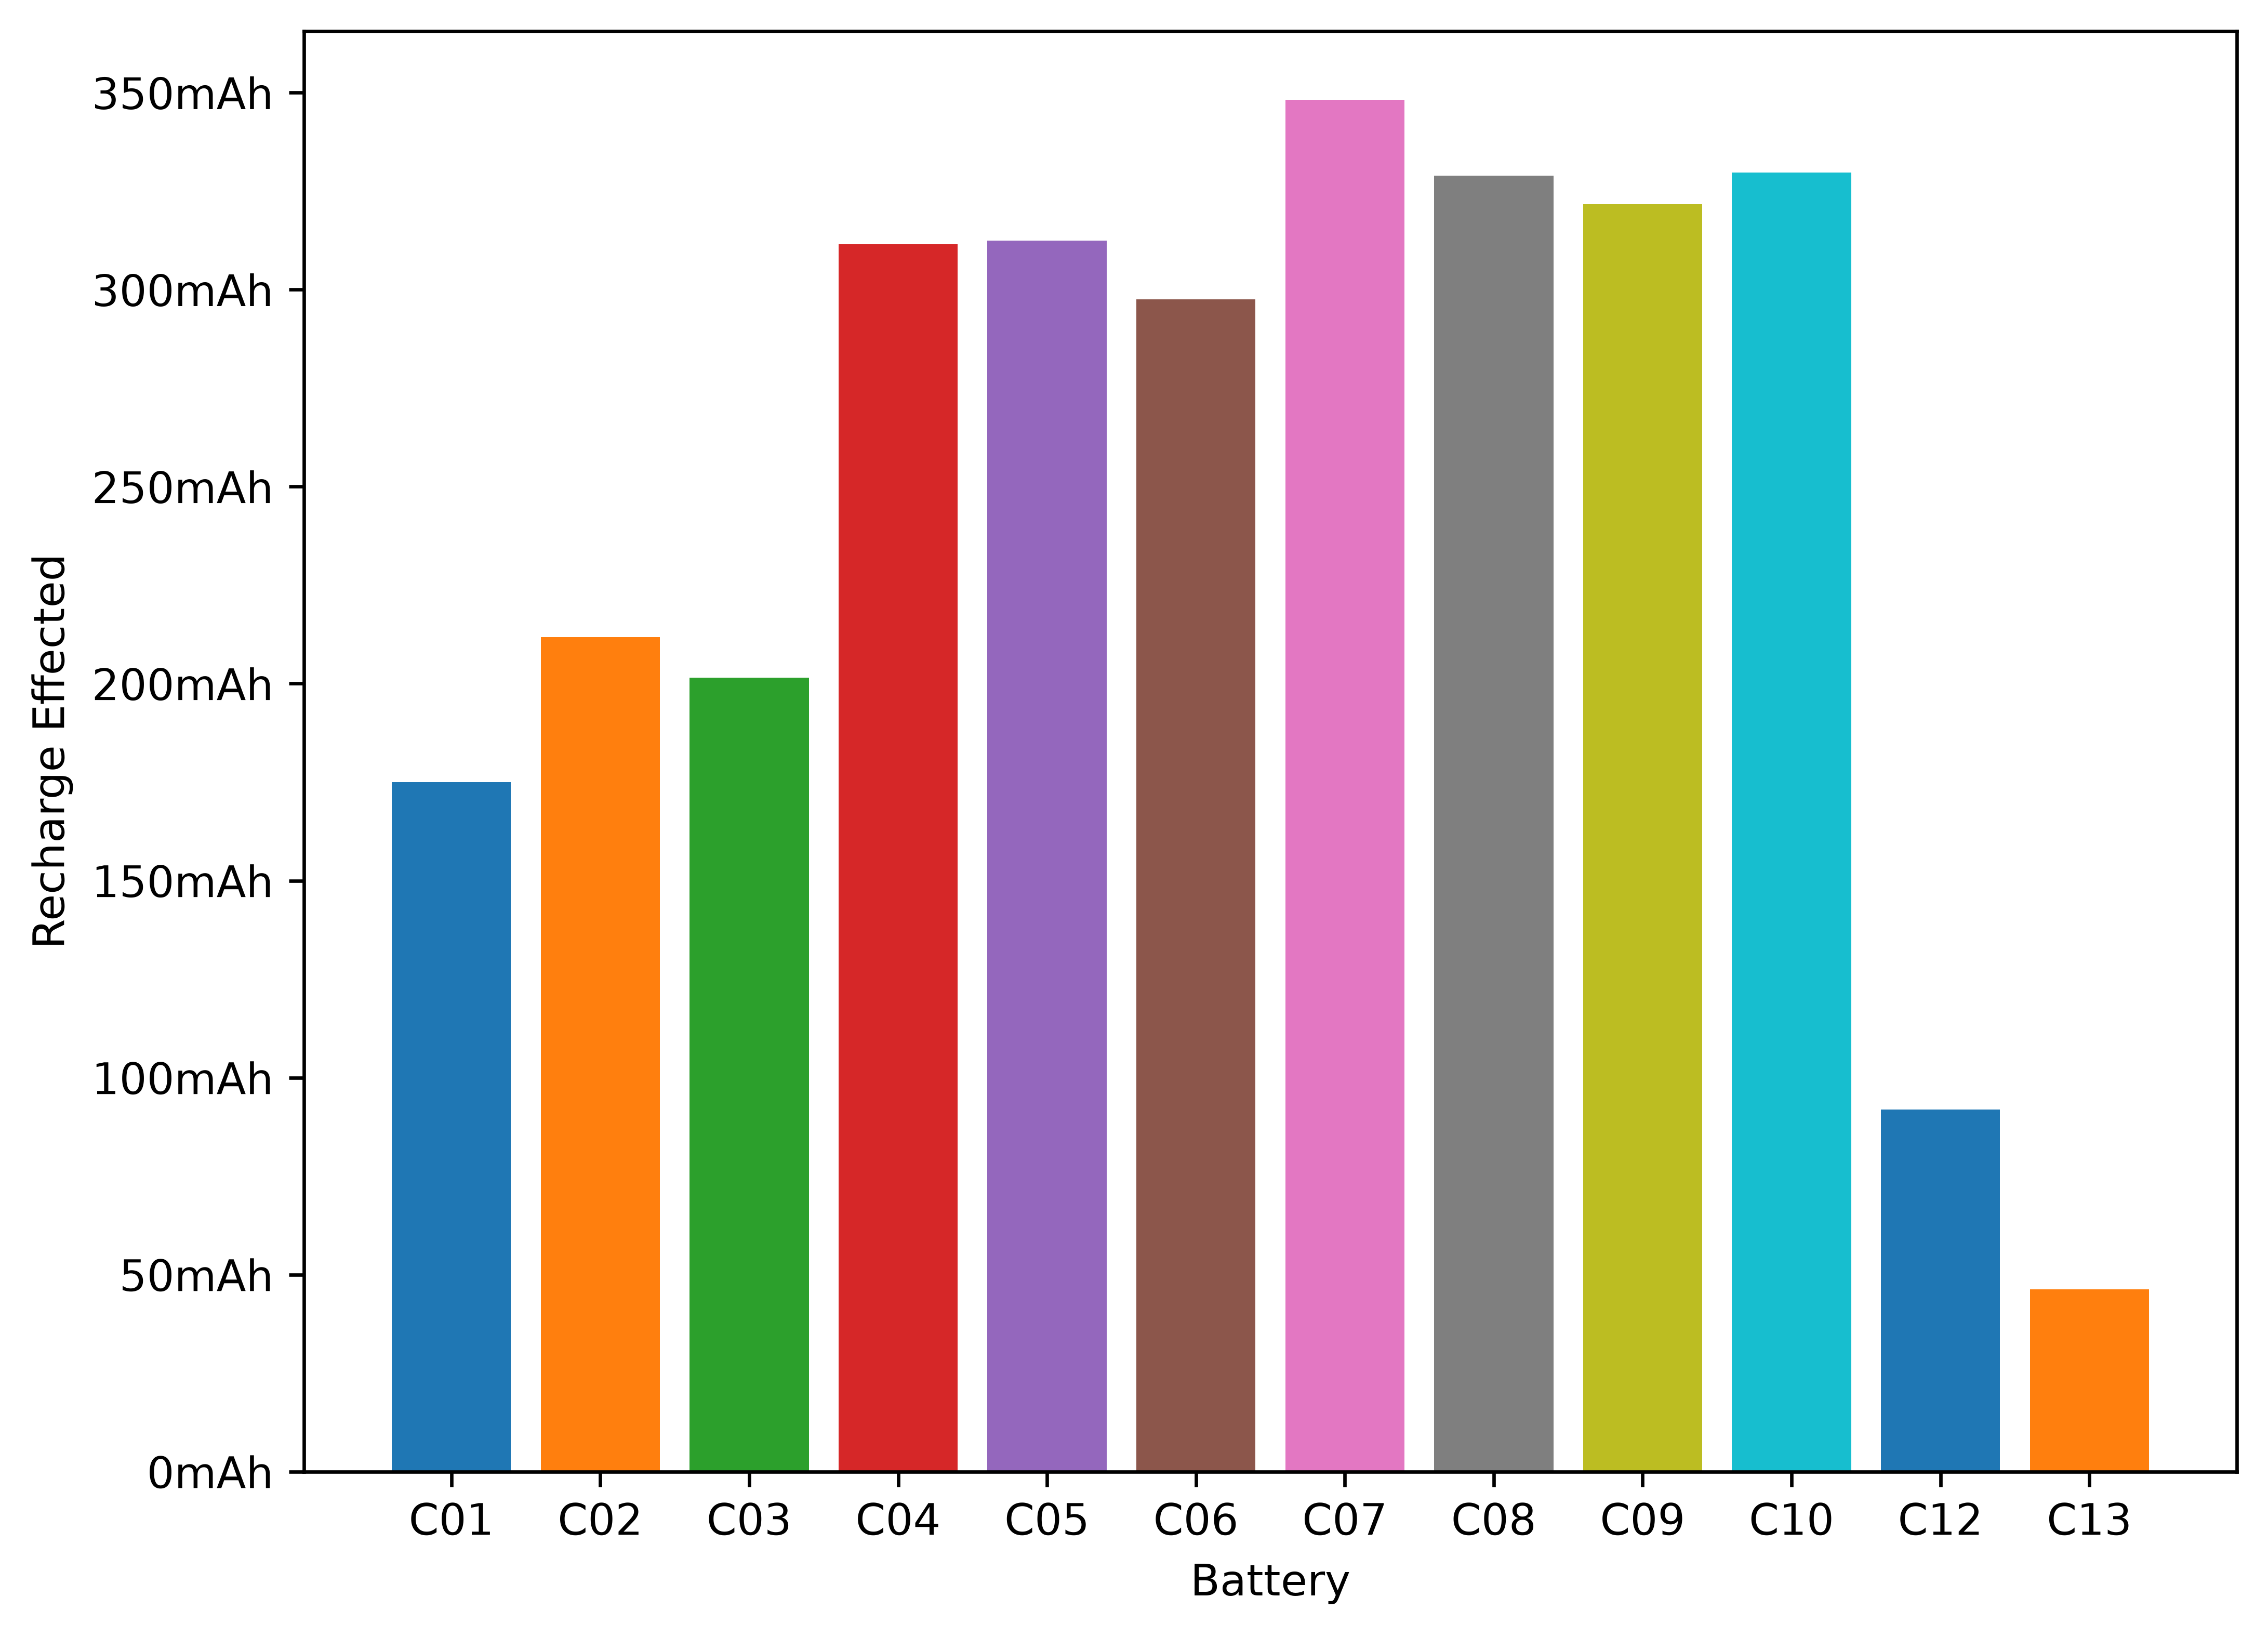

In [650]:
def plot_recharge_emf(
    emf_df: pd.DataFrame, mol_electrolyte: float, filter=None
) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 6))

    for battery_id in emf_df["Battery"].unique():
        if filter and battery_id in filter:
            continue
        row = emf_df[emf_df["Battery"] == battery_id]
        recharge_moles = calculate_recharge_ah_emf(
            row["DCV HT Pre"].values[0] / 6,
            row["DCV HT Post"].values[0] / 6,
            mol_electrolyte,
        )
        ax.bar(battery_id, recharge_moles)

    ax.set_xlabel("Battery")
    ax.set_ylabel("Recharge Effected")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000 * x:.0f}mAh"))

    return fig


plot_recharge_emf(emf_df, MOL_ELECTROLYTE, filter=FILTER_OUTLIERS)

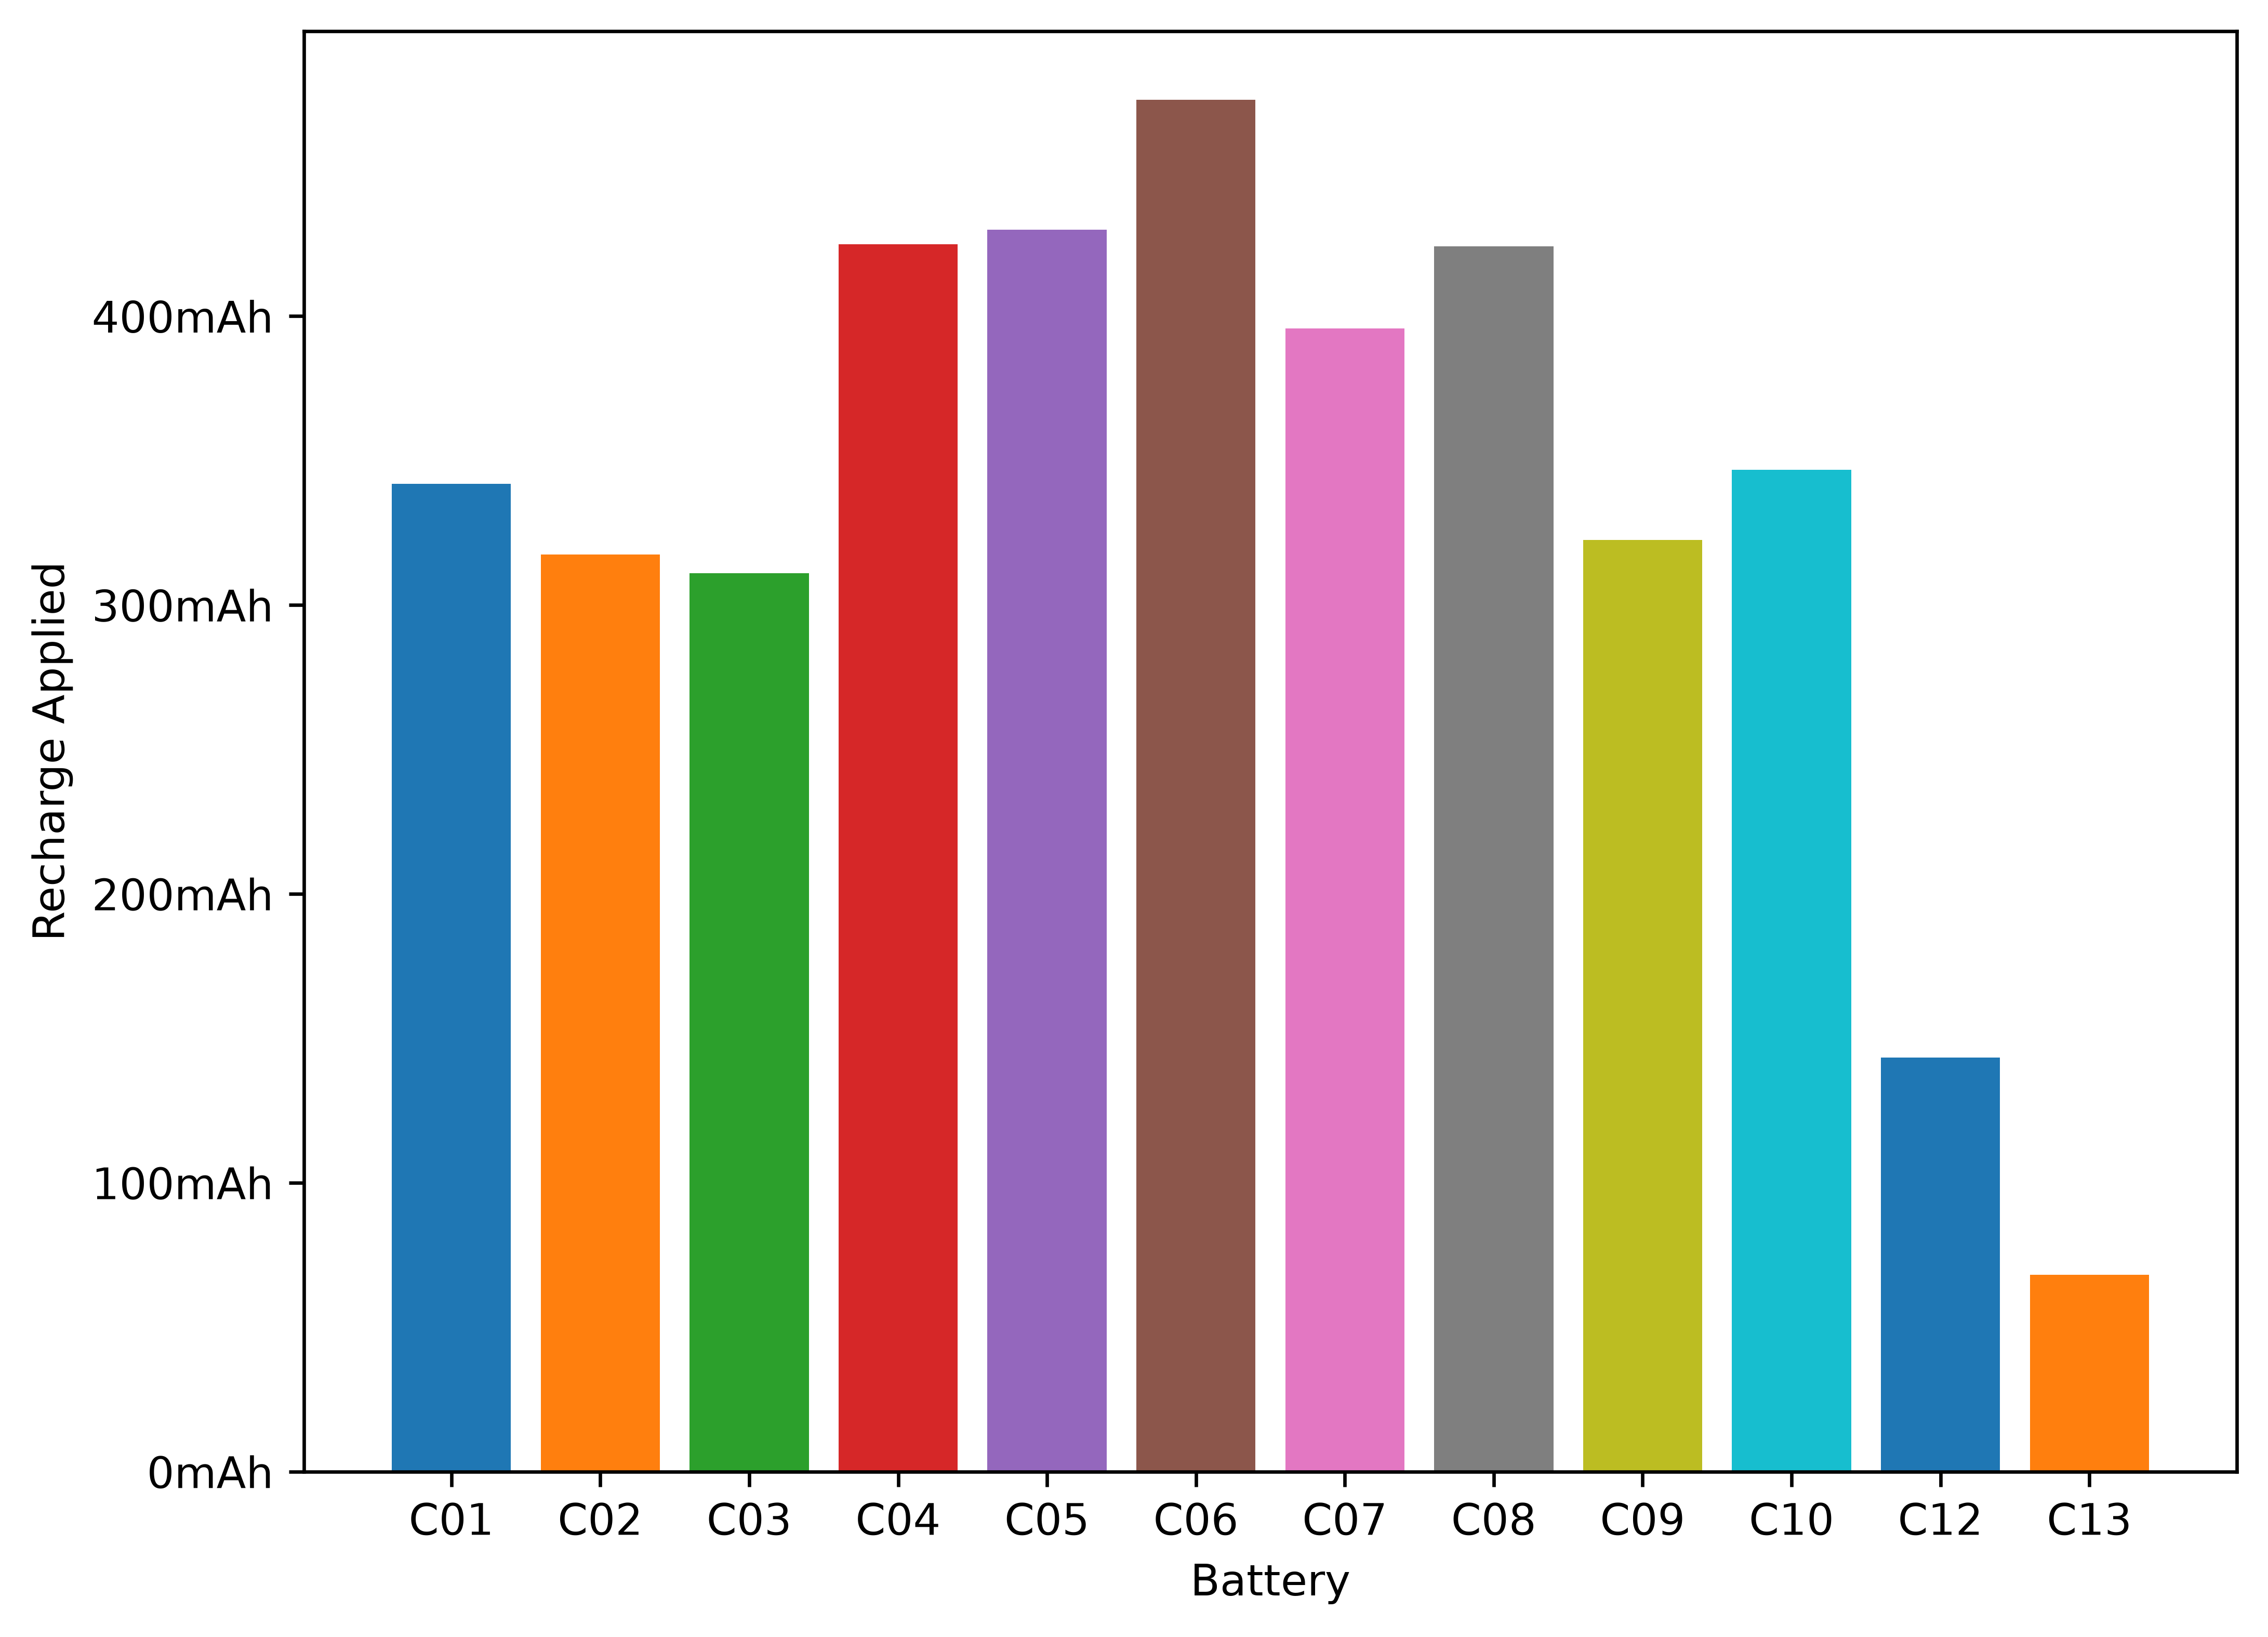

In [653]:
def plot_recharge_applied(
    recharge_data: Dict[str, pd.DataFrame], filter=None
) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 6))

    for battery_id, df in recharge_data.items():
        if filter and battery_id in filter:
            continue
        recharge_applied = df["Charge"].iloc[-1]  # Total charge applied in Ah
        ax.bar(battery_id, recharge_applied)

    ax.set_xlabel("Battery")
    ax.set_ylabel("Recharge Applied")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000 * x:.0f}mAh"))

    return fig


plot_recharge_applied(recharge_data, filter=FILTER_OUTLIERS)

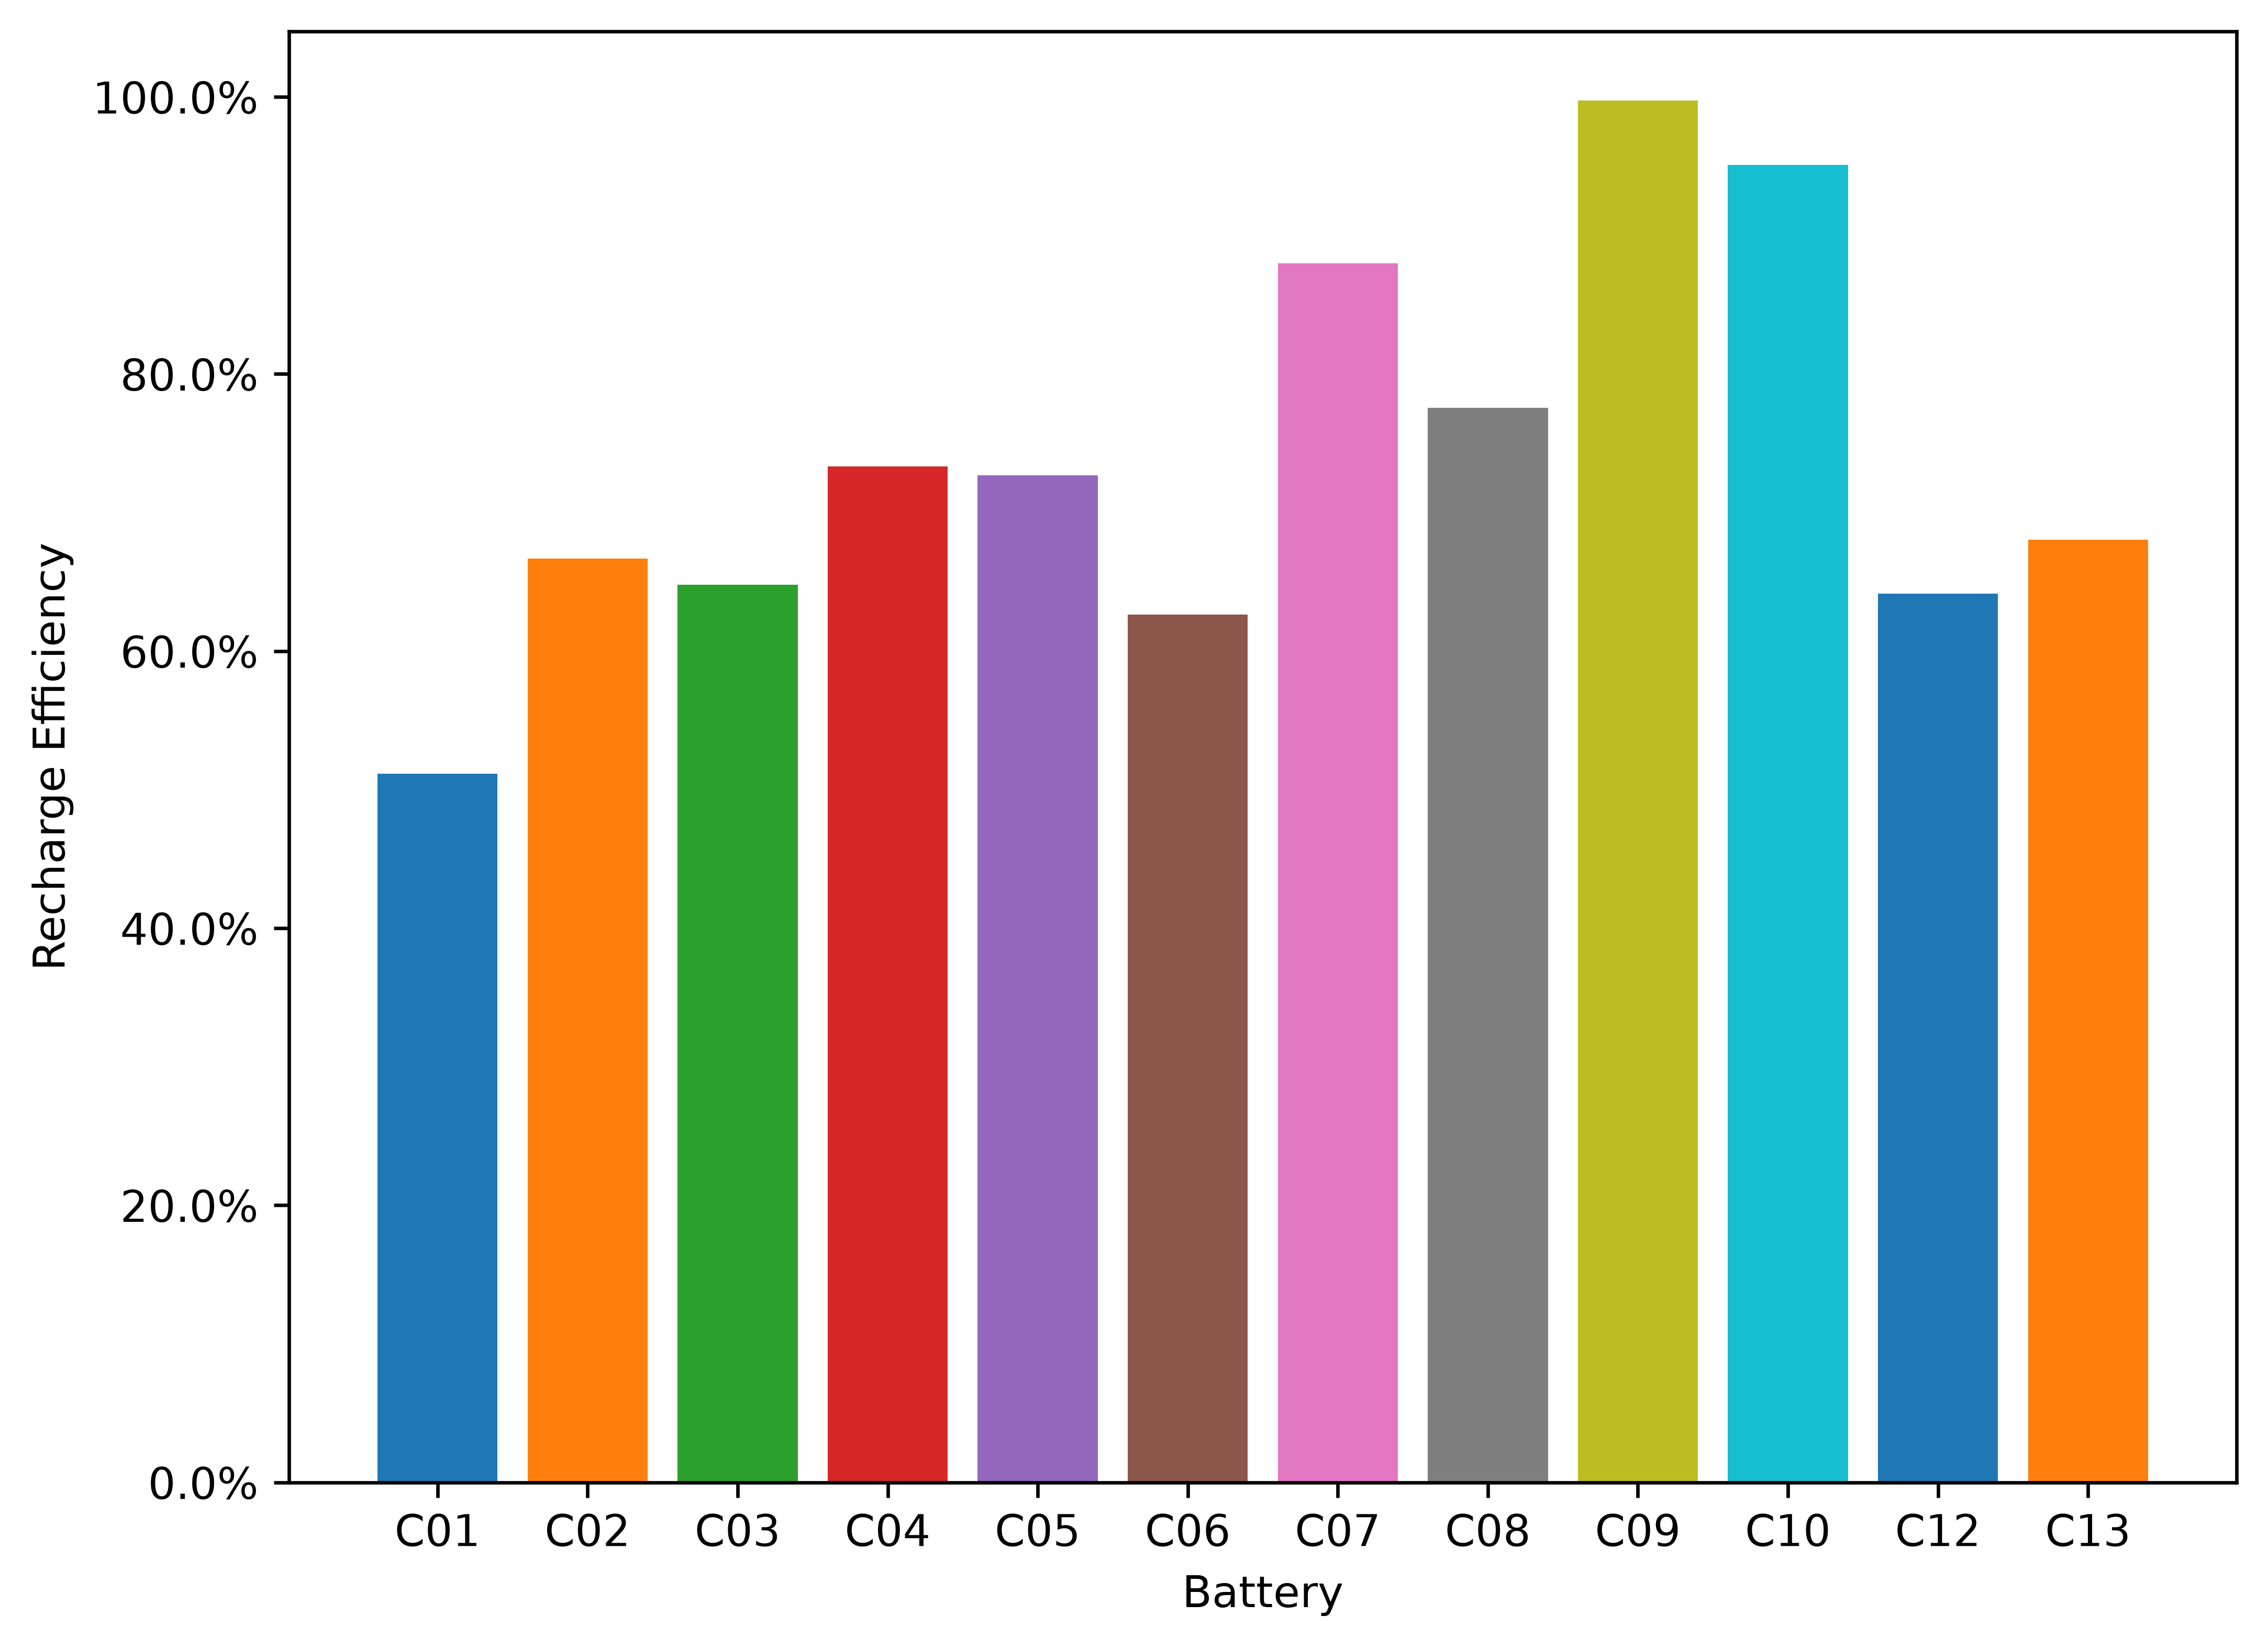

In [652]:
def plot_recharge_efficiency(
    emf_df: pd.DataFrame, recharge_data: Dict[str, pd.DataFrame], filter=None
) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 6))

    for battery_id in emf_df["Battery"].unique():
        if filter and battery_id in filter:
            continue
        row = emf_df[emf_df["Battery"] == battery_id]
        recharge_emf = calculate_recharge_ah_emf(
            row["DCV HT Pre"].values[0] / 6,
            row["DCV HT Post"].values[0] / 6,
            MOL_ELECTROLYTE,
        )
        recharge_applied = recharge_data[battery_id]["Charge"].iloc[-1]
        efficiency = recharge_emf / recharge_applied
        ax.bar(battery_id, efficiency)

    ax.set_xlabel("Battery")
    ax.set_ylabel("Recharge Efficiency")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1%}"))

    return fig


plot_recharge_efficiency(emf_df, recharge_data, filter=FILTER_OUTLIERS)

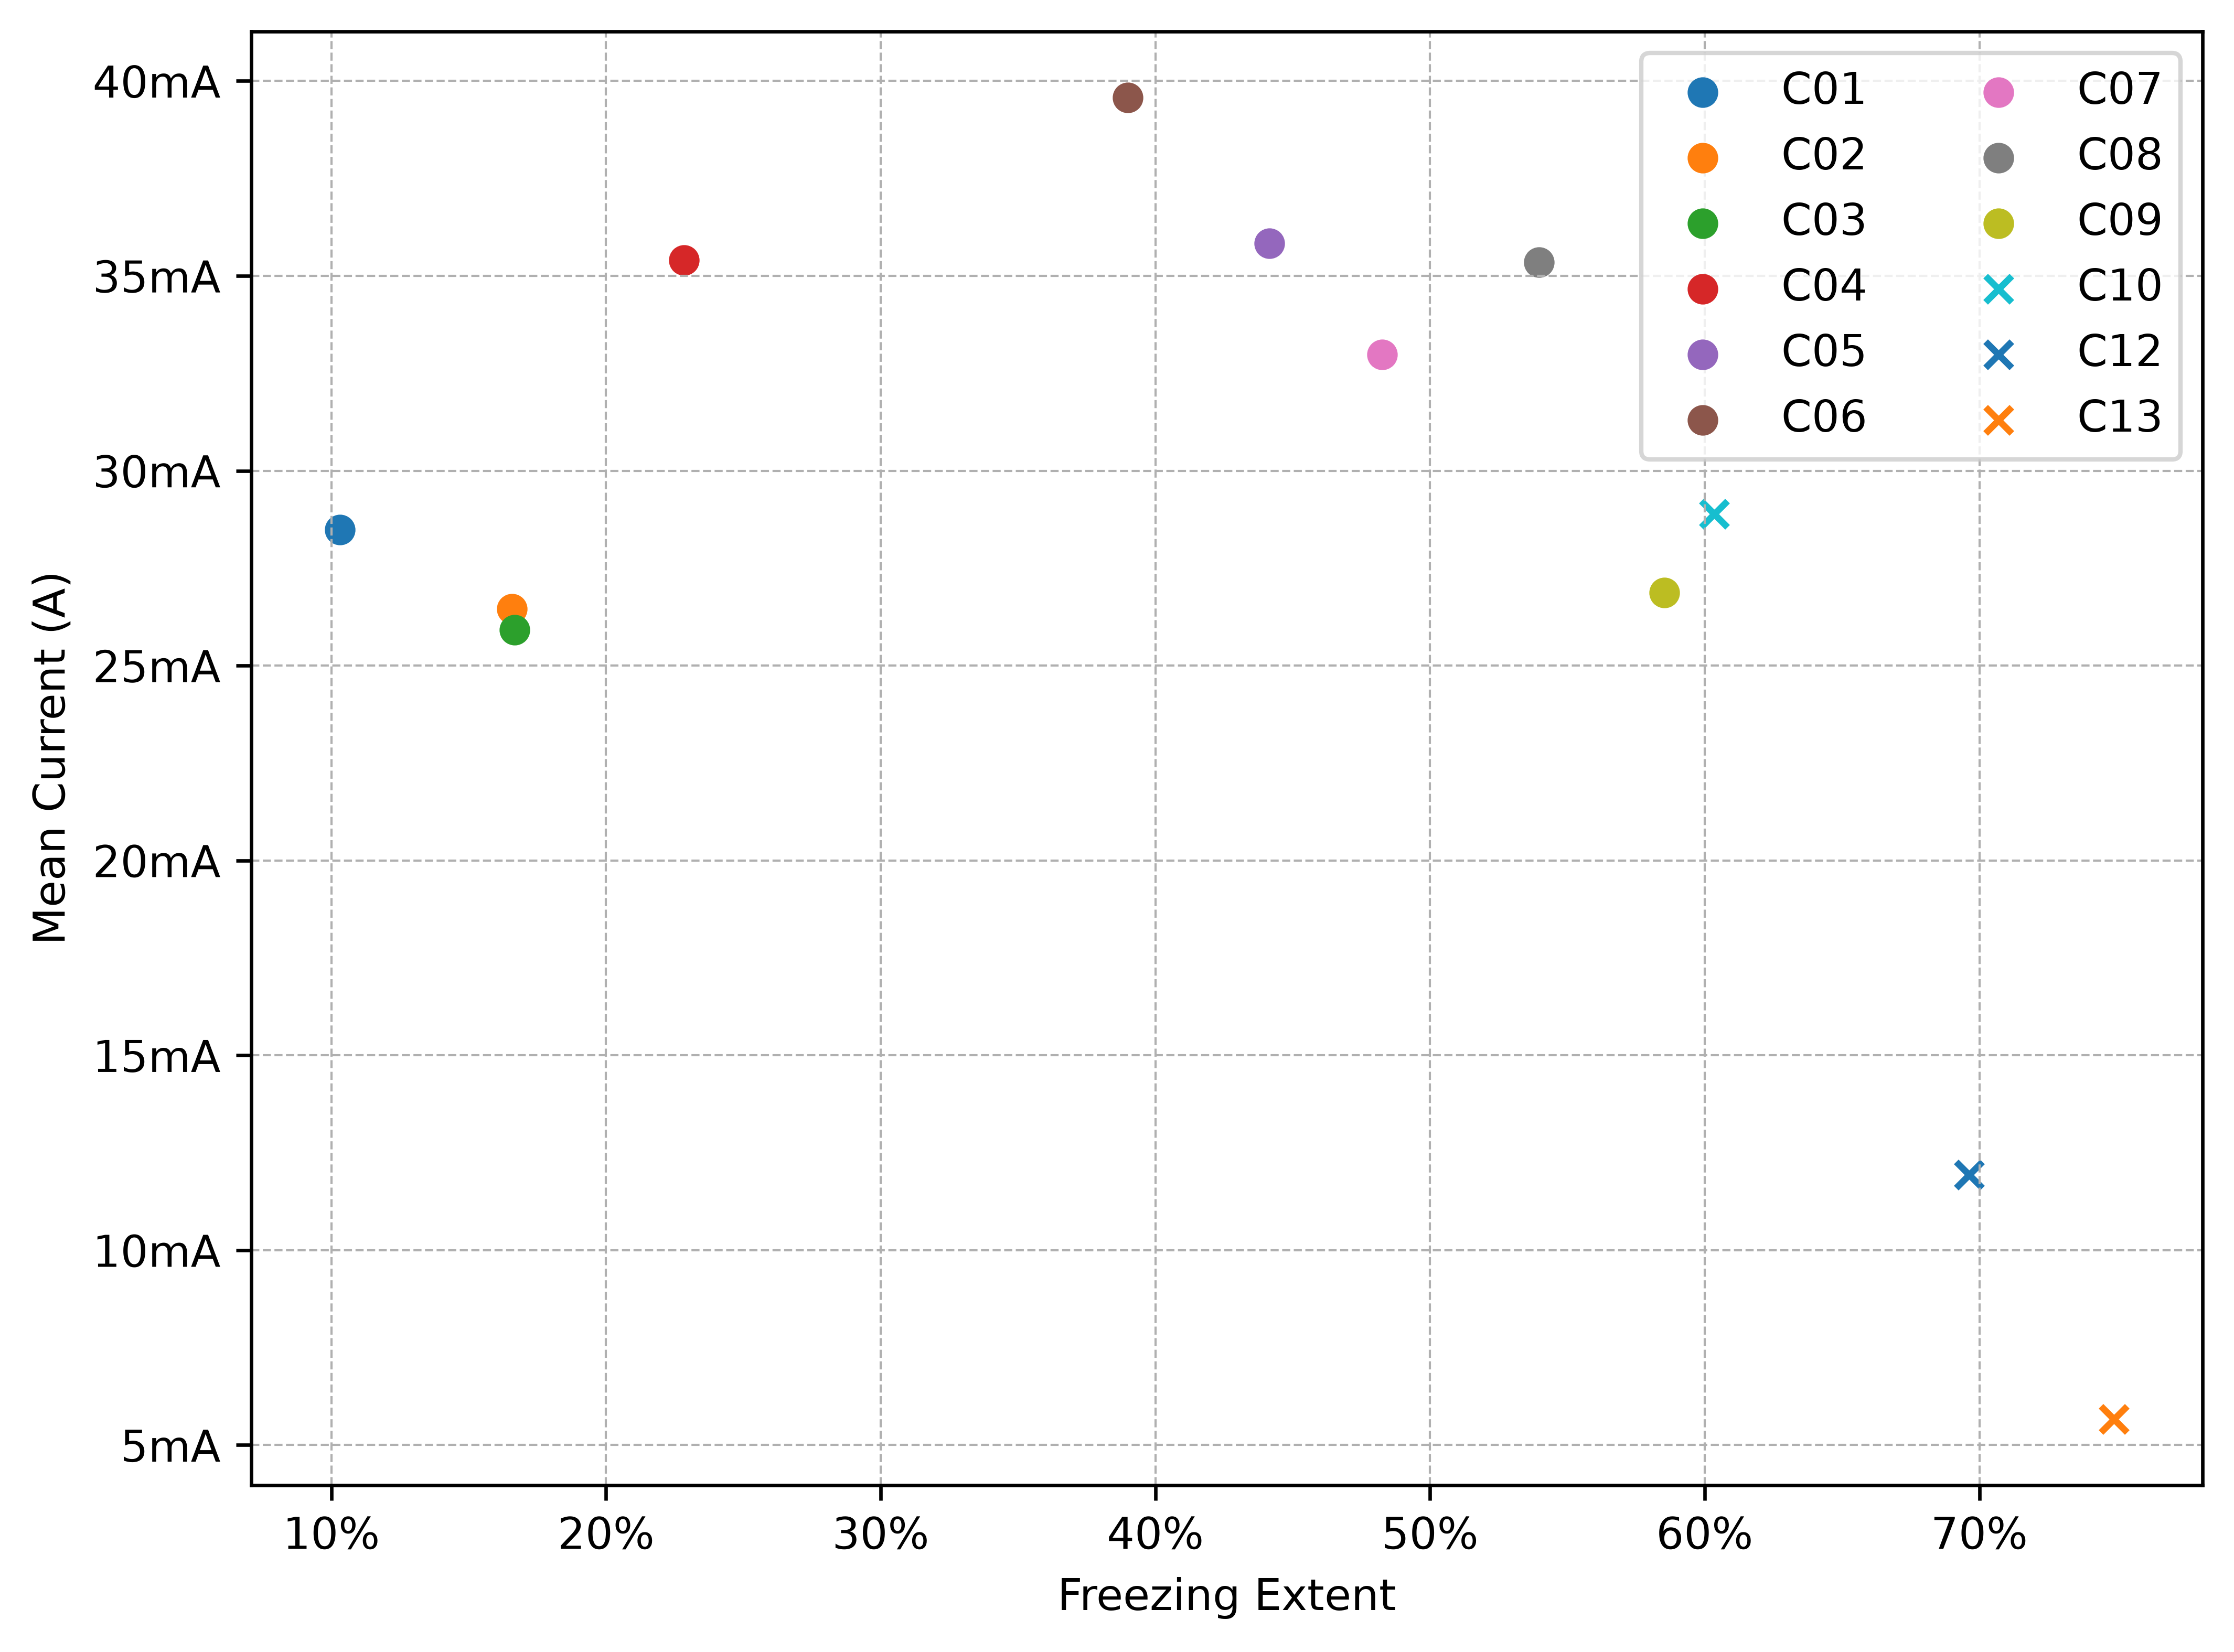

In [658]:
def plot_mean_current_vs_freezing_extent(
    recharge_data: Dict[str, pd.DataFrame],
    emf_df: pd.DataFrame,
    filter=None,
) -> Figure:
    fig, ax = plt.subplots(figsize=(8, 6))

    for battery_id in emf_df["Battery"].unique():
        if filter and battery_id in filter:
            continue
        row = emf_df[emf_df["Battery"] == battery_id]
        freezing_ext = freezing_extent(
            row["DCV HT Pre"].values[0] / 6, row["DCV LT Pre"].values[0] / 6
        )
        mean_current = recharge_data[battery_id]["Current"].mean()
        ax.scatter(
            freezing_ext,
            mean_current,
            label=f"{battery_id}",
            marker="x" if int(battery_id[1:]) >= 10 else "o",
        )

    ax.set_ylabel("Mean Current (A)")
    ax.set_xlabel("Freezing Extent")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000 * x:.0f}mA"))
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)
    ax.legend(ncol=2)

    return fig


plot_mean_current_vs_freezing_extent(recharge_data, emf_df, filter=FILTER_OUTLIERS)